# Phát hiện và phân đoạn vết nứt mặt đường bằng xử lý ảnh cổ điển

**Bài toán.** Đầu vào là **ảnh gốc** chụp mặt đường (ảnh RGB, kích thước bất kỳ). Đầu ra là **mặt nạ nhị phân** cùng kích thước với ảnh gốc, trong đó 1 = pixel thuộc vết nứt. Từ mặt nạ có thể kết luận ảnh có nứt hay không, và vết nứt nằm ở đâu.

**Ràng buộc.**
* Chỉ dùng kiến thức trong học phần (Chương 1–9, thư mục `XLA/`).
* **Không dùng mô hình học sâu hay mô hình huấn luyện sẵn.** Toàn bộ là xử lý ảnh cổ điển; tham số được chọn bằng tìm kiếm theo lưới trên một tập riêng.

**Khó khăn cốt lõi.**
1. Vết nứt rất **mảnh** (1–5 px) và chỉ chiếm khoảng 1–3% số pixel, nên dữ liệu **lệch lớp** nặng.
2. Mặt đường có **kết cấu hạt** (sỏi, nhựa đường) dễ bị nhầm thành vết nứt.
3. **Chiếu sáng không đều**: có bóng đổ, vệt sáng, độ sáng thay đổi giữa các ảnh.

## Pipeline

| Bước | Nội dung | Kỹ thuật | Chương |
|---|---|---|---|
| 1. Dữ liệu | CFD (118 ảnh) + CRACK500 (249 ảnh gốc), mặt nạ GT mức pixel, chia tune/test | — | — |
| 2. Tiền xử lý | Chuẩn hóa kích thước → ảnh xám → (cân bằng lược đồ) → lọc trung vị → bù chiếu sáng | Lấy mẫu lại, hệ màu, lọc trung vị, biến đổi điểm | C2, C3, C4 |
| 3. Xử lý chính | **Ngưỡng tam giác** trên lược đồ đã làm trơn của ảnh tỉ số I/B | Làm trơn lược đồ, tách ngưỡng tự động | C5 |
| 4. Hậu xử lý | Phép đóng → phép mở → lọc vùng theo diện tích → lọc theo độ dãn dài | Hình thái học, đặc trưng hình dạng (mômen) | C7, C8 |
| 5. Đánh giá | Dice, IoU (kèm Precision, Recall) trên tập test, so với đối chứng Otsu và Canny | Ma trận nhầm lẫn | C8 |

Các biến thể được so sánh thêm: **Sobel ∩ ngưỡng tam giác** (Ch5) và **đối xứng nền + phát triển vùng** (Ch5).

In [1]:
import os, re, json, time, zipfile, itertools, shutil
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")                                # hình JPEG cho notebook nhẹ
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9})
pd.set_option("display.precision", 3)

ROOT = os.path.abspath("..")                                   # thư mục DoAn/ (notebook nằm trong code/)
SRC = os.path.normpath(os.path.join(ROOT, "..", "pavement crack datasets"))  # dữ liệu gốc dạng zip
DATA = os.path.join(ROOT, "data")                              # dữ liệu sau khi giải nén
RES = os.path.join(ROOT, "results")                            # bảng kết quả, tham số, hình
os.makedirs(RES, exist_ok=True)
DATASETS = ["cfd", "crack500"]
RUN_TUNING = True        # False: đọc lại tham số đã tìm từ results/best_params.json
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.4.6


In [2]:
# ---- Hàm tiện ích hiển thị (dùng cho mọi bước) ----
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def show_before_after(before, after, tb, ta, title, cmap_b=None, cmap_a="gray", vmin_a=None, vmax_a=None):
    """In 5 ảnh TRƯỚC (hàng trên) và SAU (hàng dưới) một phép biến đổi không gian ảnh."""
    n = len(before)
    fig, ax = plt.subplots(2, n, figsize=(3.2 * n, 5.4))
    for j in range(n):
        ax[0, j].imshow(rgb(before[j]), cmap=cmap_b or ("gray" if before[j].ndim == 2 else None))
        ax[0, j].set_title("TRƯỚC: " + tb[j])
        ax[1, j].imshow(rgb(after[j]), cmap=cmap_a if after[j].ndim == 2 else None, vmin=vmin_a, vmax=vmax_a)
        ax[1, j].set_title("SAU: " + ta[j])
        for a in ax[:, j]:
            a.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def shp(img):
    return f"{img.shape[1]}×{img.shape[0]}" + ("×3" if img.ndim == 3 else "")

def overlay_red(img, mask, alpha=0.6):
    """Phủ mặt nạ màu đỏ lên ảnh (BGR)."""
    out = img.copy()
    red = np.zeros_like(img); red[..., 2] = 255
    out[mask] = (alpha * red[mask] + (1 - alpha) * img[mask]).astype(np.uint8)
    return out

def error_map(pred, gt):
    """Xanh lá = TP (đúng), đỏ = FP (báo nhầm), xanh dương = FN (bỏ sót). Trả về ảnh BGR."""
    m = np.zeros(gt.shape + (3,), np.uint8)
    m[pred & gt] = (0, 200, 0); m[pred & ~gt] = (0, 0, 255); m[~pred & gt] = (255, 0, 0)
    return m

---
# Bước 1 – Dữ liệu

### Nguồn
Dữ liệu lấy từ thư mục `pavement crack datasets/`. Đây là bộ sưu tập công khai các tập dữ liệu vết nứt mặt đường, được giới nghiên cứu dùng làm chuẩn so sánh.

| Tập | Mô tả | Ảnh gốc dùng | Ghi chú |
|---|---|---|---|
| **CFD** (CrackForest, Shi và cộng sự, 2016) | Ảnh mặt đường đô thị ở Bắc Kinh, chụp bằng điện thoại | `cfd_image/001–118.jpg`, 480×320 RGB | Ảnh `201–329` **không có GT** nên bị loại |
| **CRACK500** (Zhang và cộng sự 2016; Yang và cộng sự 2019) | Mặt đường ở Đại học Temple, chụp bằng điện thoại | `valdata.zip` (50) + `testdata.zip` (200), **ảnh đầy đủ** 1440×2560 đến 3264×2448 | **Không** dùng bản đã cắt nhỏ (`*crop.zip`) |

### Cách gán nhãn
Mỗi ảnh có một **mặt nạ GT nhị phân** (PNG, 0/255), do người gán nhãn **vẽ tay ở mức pixel** lên ảnh: 255 = vết nứt, 0 = nền.
* GT của CFD rất **mảnh**, phần lớn chỉ rộng 1–3 px, vẽ theo đường tâm vết nứt.
* GT của CRACK500 **dày hơn** và bao trọn bề rộng vết nứt.

### Chia tập
Tập **tune** chỉ dùng để chọn tham số. Tập **test** chỉ dùng một lần để báo cáo kết quả. Hai tập không trùng ảnh nào.

| Tập | tune | test (đánh giá) |
|---|---|---|
| CFD | 001–060 (60 ảnh) | 061–118 (**58 ảnh**) |
| CRACK500 | `valdata` (49 ảnh) | `testdata` (**200 ảnh**) |

Tổng số ảnh đánh giá là **258 ≥ 50**, đạt yêu cầu của đề.

### Hai lỗi dữ liệu phát hiện được khi chuẩn bị
1. **EXIF Orientation.** Nhiều ảnh CRACK500 có thẻ EXIF yêu cầu xoay ảnh. Nếu OpenCV đọc theo mặc định, ảnh bị xoay 90° nhưng mặt nạ GT thì không, làm lệch hoàn toàn với GT (132/250 ảnh bị ảnh hưởng). GT được vẽ trên dữ liệu pixel **chưa xoay**, nên phải đọc với cờ `IMREAD_IGNORE_ORIENTATION`.
2. **Trùng ảnh giữa val và test.** Ảnh `20160329_103807` có mặt ở cả `valdata` và `testdata`. Ảnh này bị loại khỏi tập tune để tránh **rò rỉ dữ liệu**, nên tập tune còn 49 ảnh.

In [3]:
def _decode(data, flags):
    return cv2.imdecode(np.frombuffer(data, np.uint8), flags | cv2.IMREAD_IGNORE_ORIENTATION)

def _save_pair(ds, sid, img, mask):
    for sub in ("images", "masks"):
        os.makedirs(os.path.join(DATA, ds, sub), exist_ok=True)
    cv2.imwrite(os.path.join(DATA, ds, "images", sid + ".jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    cv2.imwrite(os.path.join(DATA, ds, "masks", sid + ".png"), np.where(mask > 127, 255, 0).astype(np.uint8))

def _write_split(ds, name, ids):
    with open(os.path.join(DATA, ds, name + ".txt"), "w") as f:
        f.write("\n".join(sorted(ids)) + "\n")

def prepare_cfd():
    zi = zipfile.ZipFile(os.path.join(SRC, "CFD", "cfd_image.zip"))
    zg = zipfile.ZipFile(os.path.join(SRC, "CFD", "cfd_gt.zip"))
    gts = {os.path.splitext(os.path.basename(n))[0]: n for n in zg.namelist()
           if n.lower().endswith(".png") and "__MACOSX" not in n}
    ids = []
    for n in zi.namelist():
        sid = os.path.splitext(os.path.basename(n))[0]
        if n.lower().endswith(".jpg") and "__MACOSX" not in n and sid in gts:   # bỏ ảnh không có GT
            img, mask = _decode(zi.read(n), cv2.IMREAD_COLOR), _decode(zg.read(gts[sid]), cv2.IMREAD_GRAYSCALE)
            assert img.shape[:2] == mask.shape
            _save_pair("cfd", sid, img, mask); ids.append(sid)
    _write_split("cfd", "tune", [i for i in ids if int(i) <= 60])
    _write_split("cfd", "test", [i for i in ids if int(i) > 60])

def _crack500(zname):
    z = zipfile.ZipFile(os.path.join(SRC, "CRACK500", zname))
    names = {n for n in z.namelist() if "__MACOSX" not in n}
    ids = []
    for n in sorted(names):
        base = os.path.splitext(n)[0]
        if re.search(r"\.jpe?g$", n, re.I) and base + "_mask.png" in names:
            img, mask = _decode(z.read(n), cv2.IMREAD_COLOR), _decode(z.read(base + "_mask.png"), cv2.IMREAD_GRAYSCALE)
            assert img.shape[:2] == mask.shape, n
            sid = os.path.basename(base); _save_pair("crack500", sid, img, mask); ids.append(sid)
    return ids

def prepare_crack500():
    tune, test = _crack500("valdata.zip"), _crack500("testdata.zip")   # test ghi sau -> file trùng tên là bản test
    dup = set(tune) & set(test)
    print("Trùng tên giữa valdata và testdata (loại khỏi tune):", sorted(dup))
    _write_split("crack500", "tune", [i for i in tune if i not in dup])
    _write_split("crack500", "test", test)

if not os.path.exists(os.path.join(DATA, "cfd", "test.txt")):
    prepare_cfd()
if not os.path.exists(os.path.join(DATA, "crack500", "test.txt")):
    prepare_crack500()

def ids_of(ds, split):
    return open(os.path.join(DATA, ds, split + ".txt")).read().split()

def read_pair(ds, sid):
    img = cv2.imread(os.path.join(DATA, ds, "images", sid + ".jpg"))
    gt = cv2.imread(os.path.join(DATA, ds, "masks", sid + ".png"), cv2.IMREAD_GRAYSCALE) > 127
    return img, gt

In [4]:
# Thống kê dữ liệu: số ảnh, kích thước, tỉ lệ pixel nứt
rows = []
for ds in DATASETS:
    for split in ("tune", "test"):
        sizes, frac = {}, []
        for sid in ids_of(ds, split):
            gt = cv2.imread(os.path.join(DATA, ds, "masks", sid + ".png"), cv2.IMREAD_GRAYSCALE) > 127
            k = f"{gt.shape[1]}×{gt.shape[0]}"; sizes[k] = sizes.get(k, 0) + 1
            frac.append(gt.mean() * 100)
        rows.append({"tập": ds, "phần": split, "số ảnh": len(frac),
                     "kích thước (phổ biến nhất)": ", ".join(f"{k} ({v})" for k, v in sorted(sizes.items(), key=lambda x: -x[1])[:3]),
                     "% pixel nứt TB": np.mean(frac), "min": np.min(frac), "max": np.max(frac)})
stats = pd.DataFrame(rows); stats

,tập,phần,số ảnh,kích thước (phổ biến nhất),% pixel nứt TB,min,max
0,cfd,tune,60,480×320 (60),1.635,0.352,6.219
1,cfd,test,58,480×320 (58),1.596,0.725,6.331
2,crack500,tune,49,"2560×1440 (46), 2592×1936 (3)",2.447,0.309,8.683
3,crack500,test,200,"2560×1440 (146), 3264×2448 (36), 2592×1936 (13)",2.494,0.150,7.006


**Nhận xét.**
* Trung bình chỉ khoảng **1.5–2.5% số pixel là vết nứt**. Một bộ phân đoạn "đoán toàn nền" vẫn đạt accuracy khoảng 98%. Vì vậy **không dùng accuracy** (Ch8: dữ liệu lệch lớp thì accuracy dễ đánh lừa), mà dùng **Dice và IoU**.
* Kích thước ảnh rất khác nhau: CFD 480×320, CRACK500 lớn tới 3264×2448. Do đó cần **chuẩn hóa kích thước** ở bước 2.

Dưới đây là 5 ảnh mẫu (3 CFD, 2 CRACK500, đều lấy từ tập **tune**), dùng làm ví dụ minh họa xuyên suốt notebook.

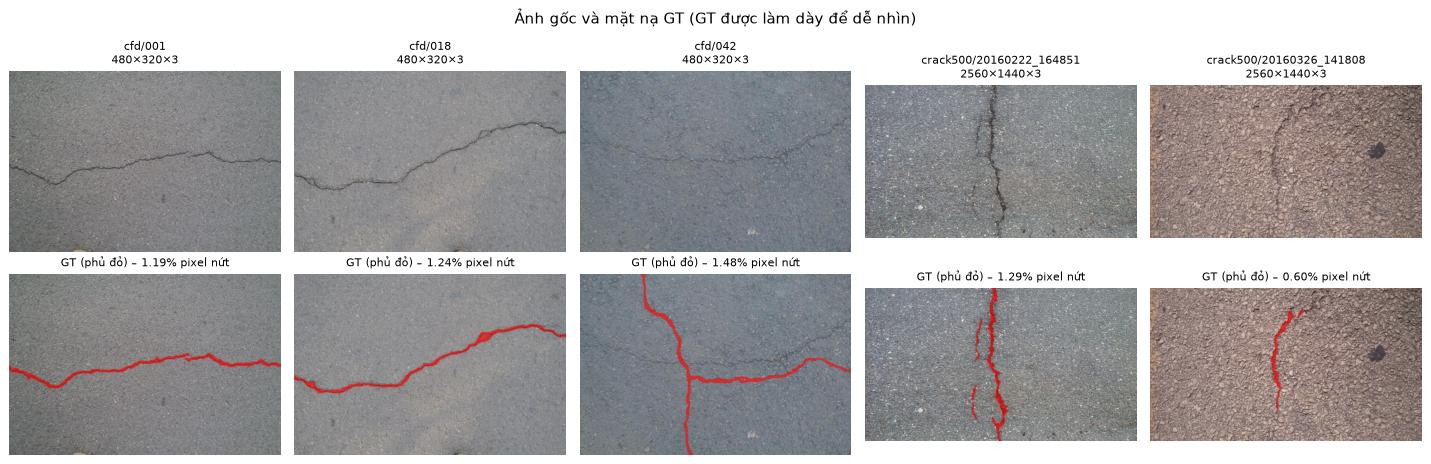

In [5]:
SAMPLES = [("cfd", "001"), ("cfd", "018"), ("cfd", "042"),
           ("crack500", ids_of("crack500", "tune")[3]), ("crack500", ids_of("crack500", "tune")[20])]
S_IMG, S_GT = zip(*[read_pair(ds, sid) for ds, sid in SAMPLES])
S_NAME = [f"{ds}/{sid}" for ds, sid in SAMPLES]

fig, ax = plt.subplots(2, 5, figsize=(16, 5.4))
for j in range(5):
    ax[0, j].imshow(rgb(S_IMG[j])); ax[0, j].set_title(f"{S_NAME[j]}\n{shp(S_IMG[j])}")
    ax[1, j].imshow(rgb(overlay_red(S_IMG[j], cv2.dilate(S_GT[j].astype(np.uint8), np.ones((3, 3)) if S_IMG[j].shape[0] < 1000 else np.ones((9, 9))) > 0)))
    ax[1, j].set_title(f"GT (phủ đỏ) – {S_GT[j].mean()*100:.2f}% pixel nứt")
    for a in ax[:, j]: a.axis("off")
fig.suptitle("Ảnh gốc và mặt nạ GT (GT được làm dày để dễ nhìn)", fontsize=12); plt.tight_layout(); plt.show()

---
# Bước 2 – Tiền xử lý (Chương 2, 3, 4)

Thứ tự các bước: **(2.1) chuẩn hóa kích thước → (2.2) chuyển ảnh xám → (2.3) cân bằng lược đồ (tùy chọn) → (2.4) lọc trung vị → (2.5) bù chiếu sáng.**
Mọi bước đều **thay đổi không gian ảnh** (kích thước, hệ màu hoặc miền cường độ), nên mỗi bước đều in 5 ảnh mẫu trước và sau biến đổi.

Tham số được chọn bằng tìm kiếm theo lưới trên tập tune (xem phần *Chọn tham số*). Các giá trị dùng để minh họa trong phần này là **giá trị cuối cùng đã chọn cho CFD**.

In [6]:
P_DEMO = dict(size=480, equalize=False, median=3, bg=61, hist_w=3)   # = tham số đã chọn cho CFD (xem phần Chọn tham số)

## 2.1 Chuẩn hóa kích thước (Ch2: lấy mẫu, độ phân giải không gian)

* **Dùng gì:** lấy mẫu lại (resample) sao cho **cạnh dài = 480 px**, giữ nguyên tỉ lệ khung hình; nội suy `INTER_AREA`.
* **Tại sao:**
  * Mọi tham số phía sau đều tính bằng **pixel**: cửa sổ lọc trung vị, cửa sổ ước lượng nền, phần tử cấu trúc, ngưỡng diện tích. Nếu không đưa ảnh về cùng một thang đo, vùng 60 px trên ảnh CFD 480×320 và trên ảnh CRACK500 3264×2448 có ý nghĩa vật lý hoàn toàn khác nhau.
  * Ảnh CRACK500 gốc có tới 8 triệu pixel; thu nhỏ khoảng 5 lần giúp xử lý nhanh hơn khoảng 30 lần.
* **Tham số:**
  * `size = 480`: bằng đúng kích thước gốc của CFD, nên CFD **không bị biến đổi** và không mất thông tin. Một vết nứt CRACK500 rộng 15–30 px ở ảnh gốc còn 3–6 px sau khi thu nhỏ, vẫn đủ để nhận ra.
  * `INTER_AREA`: khi **thu nhỏ**, phép này lấy trung bình vùng điểm ảnh nên tránh được răng cưa (aliasing). Nội suy láng giềng gần nhất có thể làm "đứt" vết nứt mảnh.
* **Đánh giá vẫn ở độ phân giải gốc:** mặt nạ dự đoán được phóng ngược về kích thước gốc bằng `INTER_NEAREST` (giữ giá trị nhị phân) rồi mới so với GT gốc.

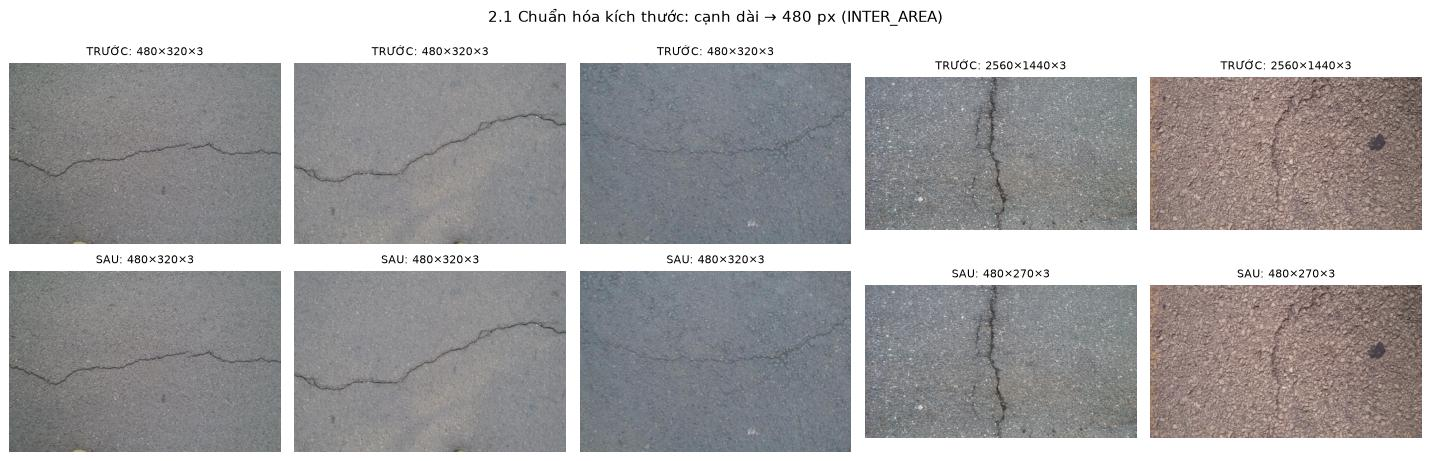

In [7]:
def resize_long_side(img, size, interp=cv2.INTER_AREA):
    h, w = img.shape[:2]
    s = size / max(h, w)
    if abs(s - 1) < 1e-6:
        return img.copy()
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=interp)

S_SMALL = [resize_long_side(im, P_DEMO["size"]) for im in S_IMG]
show_before_after(S_IMG, S_SMALL, [shp(x) for x in S_IMG], [shp(x) for x in S_SMALL],
                  "2.1 Chuẩn hóa kích thước: cạnh dài → 480 px (INTER_AREA)")

Ảnh CFD giữ nguyên 480×320. Ảnh CRACK500 được thu từ khoảng 2560×1440 về 480×270, nội dung không đổi mà chỉ giảm số điểm ảnh.

## 2.2 Chuyển sang ảnh xám (Ch4: hệ màu)

* **Dùng gì:** chuyển BGR sang mức xám theo công thức độ chói `Y = 0.299R + 0.587G + 0.114B` (`cv2.COLOR_BGR2GRAY`). Ảnh đổi từ không gian màu 3 kênh sang 1 kênh cường độ.
* **Tại sao:**
  * Vết nứt khác nền ở **độ sáng** (vết nứt là khe hở, ít nhận ánh sáng nên tối hơn) chứ **không khác về màu**: mặt đường và vết nứt cùng tông xám hoặc nâu.
  * Ở hệ HSV, kênh H (sắc độ) gần như vô nghĩa với ảnh ít bão hòa màu như mặt đường. Kênh V lấy max(R, G, B) nên nhạy với nhiễu ở từng kênh.
  * Trọng số của Y mô phỏng độ nhạy của mắt người (tế bào nón, Ch2). Kênh G có trọng số lớn nhất và cũng là kênh ít nhiễu nhất của cảm biến Bayer.
* **Tham số:** không có, vì hệ số được cố định theo chuẩn ITU-R BT.601.

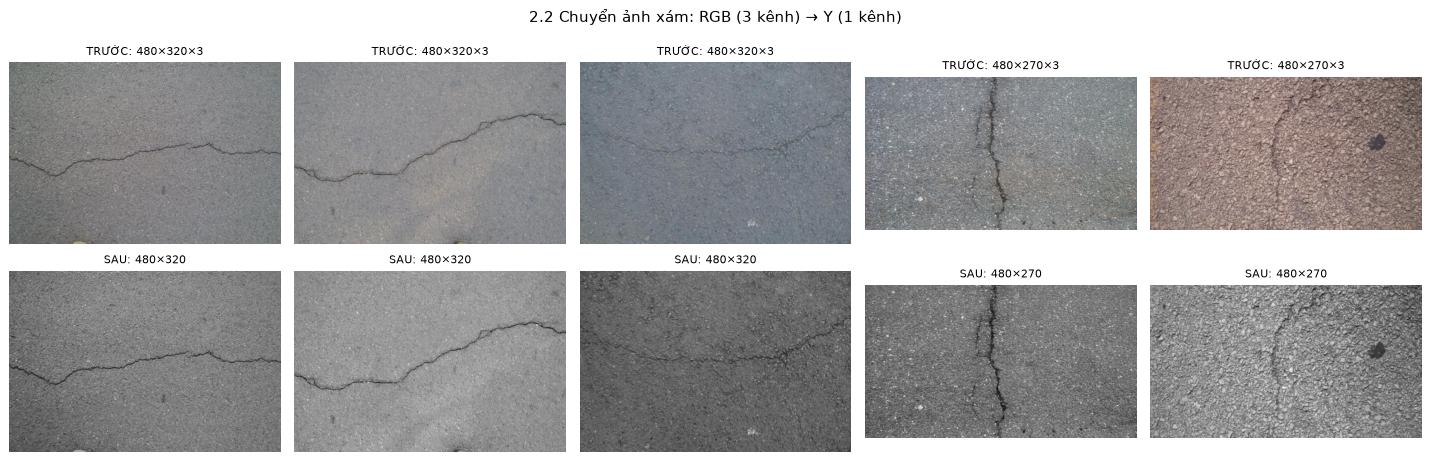

In [8]:
def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

S_GRAY = [to_gray(x) for x in S_SMALL]
show_before_after(S_SMALL, S_GRAY, [shp(x) for x in S_SMALL], [shp(x) for x in S_GRAY],
                  "2.2 Chuyển ảnh xám: RGB (3 kênh) → Y (1 kênh)")

## 2.3 Cân bằng lược đồ xám (Ch3) – đã thử, **không dùng**

* **Dùng gì:** cân bằng lược đồ toàn cục (`cv2.equalizeHist`), tức biến đổi mức xám theo hàm phân phối tích lũy (CDF) để lược đồ trải đều trên [0, 255].
* **Tại sao đưa vào thử:** giúp làm rõ vết nứt ở ảnh thiếu sáng hoặc có tương phản thấp.
* **Tham số:** `equalize ∈ {False, True}`, được đưa vào tìm kiếm theo lưới.
* **Kết quả và lý do loại bỏ:** trên **cả hai** tập tune, cấu hình tốt nhất đều là `equalize = False` (xem phần chọn tham số). Có hai lý do:
  1. Cân bằng lược đồ khuếch đại **toàn bộ** tương phản, kể cả kết cấu hạt của mặt đường, nên số pixel nền bị báo nhầm tăng lên.
  2. Đây là phép biến đổi **phi tuyến**, làm sai lệch tỉ số I/B ở bước bù chiếu sáng (bước 2.5), vốn dựa trên giả định nền đồng nhất.

  Ảnh dưới đây cho thấy kết cấu nền bị đẩy mạnh lên sau khi cân bằng.

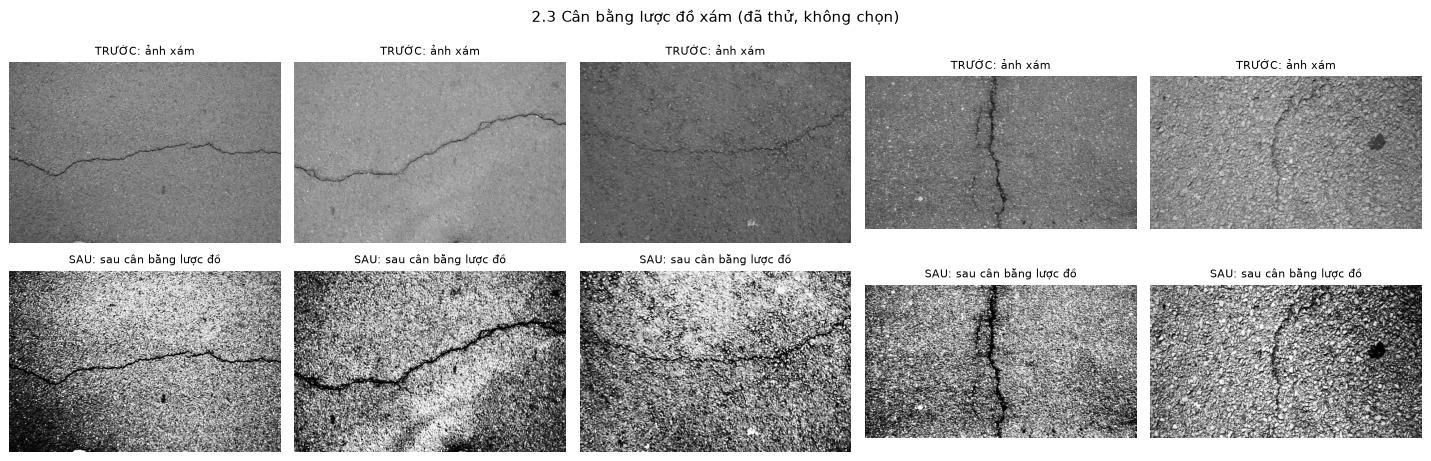

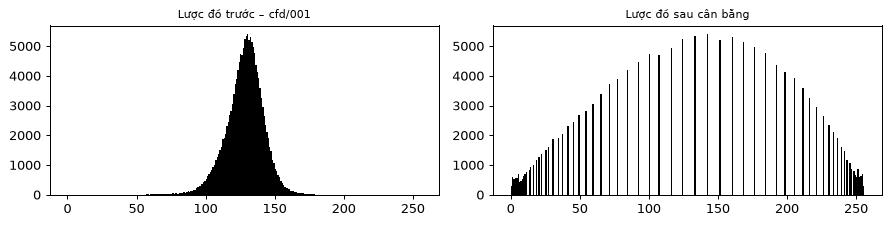

In [9]:
S_EQ = [cv2.equalizeHist(g) for g in S_GRAY]
show_before_after(S_GRAY, S_EQ, ["ảnh xám"] * 5, ["sau cân bằng lược đồ"] * 5,
                  "2.3 Cân bằng lược đồ xám (đã thử, không chọn)")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6))
ax[0].hist(S_GRAY[0].ravel(), 256, range=(0, 256), color="k"); ax[0].set_title(f"Lược đồ trước – {S_NAME[0]}")
ax[1].hist(S_EQ[0].ravel(), 256, range=(0, 256), color="k"); ax[1].set_title("Lược đồ sau cân bằng")
plt.tight_layout(); plt.show()

## 2.4 Khử nhiễu bằng lọc trung vị (Ch3: lọc không gian phi tuyến)

* **Dùng gì:** lọc trung vị cửa sổ `k×k` (`cv2.medianBlur`): mỗi pixel được thay bằng **trung vị** của các pixel lân cận.
* **Tại sao chọn trung vị thay vì lọc trung bình hay Gauss:**
  * Nhiễu trên mặt đường chủ yếu là các **hạt sỏi** nhỏ, sáng hoặc tối xen kẽ, có tính chất giống **nhiễu muối tiêu**. Theo Ch3, lọc trung vị là bộ lọc phù hợp nhất cho loại nhiễu này.
  * Lọc trung bình và Gauss làm **nhòe biên**, khiến vết nứt mảnh 1–2 px bị "loãng" ra và mờ đi. Lọc trung vị **giữ biên** và không làm nhòe. Một đốm cô lập bị xóa hoàn toàn. Một nét tối rộng **≥ 2 px** được giữ nguyên với cửa sổ 3×3 (6/9 pixel trong cửa sổ là tối nên trung vị vẫn tối), còn nét rộng 1 px thì bị xóa (chỉ 3/9 pixel tối). Vì vậy k càng lớn thì càng xóa mất nhiều vết nứt mảnh.
* **Tham số:** `median ∈ {0 (tắt), 3, 5}`, chọn bằng tìm theo lưới.
  * k = 3 hoặc 5 đủ để xóa hạt sỏi cỡ 1–2 px.
  * k ≥ 7 bắt đầu xóa luôn vết nứt mảnh nên không xét.
* **Giá trị chọn: `median = 3` cho cả hai tập.** Dice trên tập tune:

  | median | 0 | **3** | 5 |
  |---|---|---|---|
  | CFD | 0.496 | **0.516** | 0.498 |
  | CRACK500 | 0.592 | **0.638** | 0.626 |

  Không lọc thì nhiễu hạt bị gán nhầm thành vết nứt. Lọc k = 5 thì bắt đầu làm mờ vết nứt mảnh của CFD.

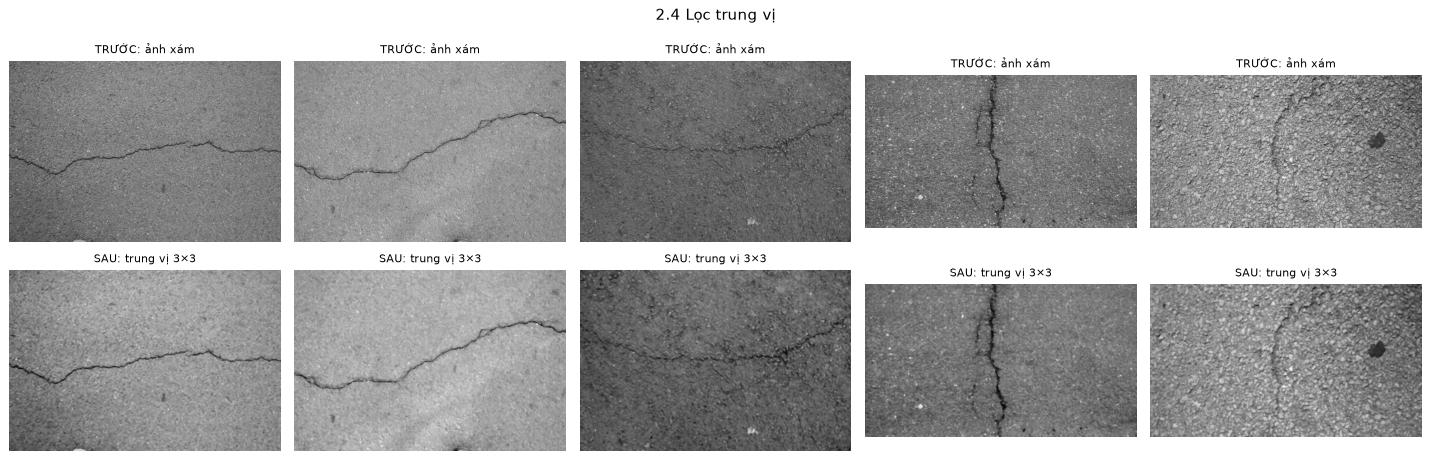

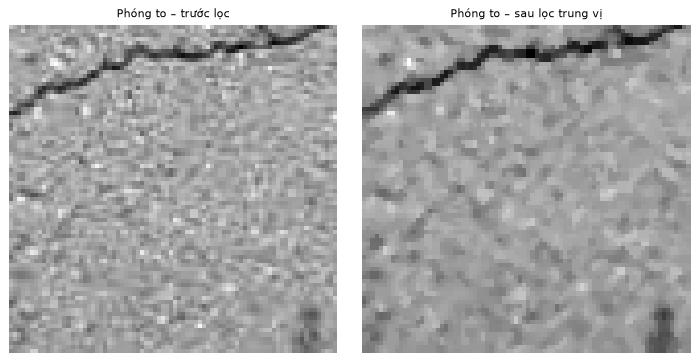

In [10]:
S_MED = [cv2.medianBlur(g, P_DEMO["median"]) for g in S_GRAY]
show_before_after(S_GRAY, S_MED, ["ảnh xám"] * 5, [f"trung vị {P_DEMO['median']}×{P_DEMO['median']}"] * 5,
                  "2.4 Lọc trung vị")
# Phóng to một vùng nhỏ để thấy rõ tác dụng
y, x = 150, 200
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(S_GRAY[0][y:y+80, x:x+80], cmap="gray"); ax[0].set_title("Phóng to – trước lọc")
ax[1].imshow(S_MED[0][y:y+80, x:x+80], cmap="gray"); ax[1].set_title("Phóng to – sau lọc trung vị")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2.5 Bù chiếu sáng không đều: ảnh tỉ số I/B (Ch3: lọc trung vị + biến đổi điểm)

* **Dùng gì:**
  1. Ước lượng **ảnh nền** B bằng lọc trung vị với cửa sổ **lớn** `bg×bg`.
  2. Tính **ảnh tỉ số** `R = 128 · I / B`, rồi cắt về [0, 255].

  Kết quả là ảnh được chuyển sang miền cường độ **tương đối so với nền**. Pixel nền có R ≈ 128, pixel tối hơn nền có R < 128.
* **Tại sao:**
  * Vết nứt rất mảnh so với cửa sổ (3–6 px so với 21–61 px), nên chiếm rất ít pixel trong cửa sổ. Trung vị của cửa sổ vì vậy chính là **mức xám nền cục bộ**, và vết nứt bị "xóa" khỏi B.
  * Bóng đổ và độ sáng thay đổi **chậm** trong không gian nên đều được giữ trong B. Khi chia I cho B, các biến đổi chậm này bị **triệt tiêu**, chỉ còn lại các cấu trúc tối nhỏ như vết nứt.
  * Sau bước này, lược đồ xám của **mọi ảnh** đều có một đỉnh nền gần 128 và gần đối xứng, còn vết nứt tạo thành **đuôi tối**. Nhờ vậy một quy tắc tách ngưỡng tự động duy nhất (bước 3) dùng được cho mọi ảnh.
  * Dùng **phép chia** thay vì phép trừ I − B vì độ sáng tác động theo kiểu **nhân**: vết nứt trong bóng râm và ngoài nắng có cùng tỉ lệ tối so với nền, nhưng hiệu số thì khác nhau.
* **Tham số:**
  * `bg ∈ {0 (tắt), 21, 41, 61}`, chọn bằng tìm theo lưới. Cửa sổ phải **lớn hơn nhiều so với bề rộng vết nứt** (> 2 lần) để trung vị bỏ qua được vết nứt, nhưng **nhỏ hơn kích thước vệt bóng đổ** để vẫn theo kịp biến đổi chiếu sáng.
  * Hệ số 128 chỉ là hằng số đưa giá trị về giữa thang 8-bit, không ảnh hưởng tới kết quả.
* **Giá trị chọn: `bg = 61` (CFD), `bg = 41` (CRACK500).** Dice trên tập tune:

  | bg | 0 (tắt) | 21 | 41 | 61 |
  |---|---|---|---|---|
  | CFD | 0.377 | 0.489 | 0.513 | **0.516** |
  | CRACK500 | 0.576 | 0.600 | **0.638** | 0.634 |

  Đây là bước **đóng góp lớn nhất** trong phần tiền xử lý: tắt bước này thì Dice giảm 0.06–0.14. Cửa sổ 21 quá nhỏ: ở chỗ vết nứt rộng hoặc giao nhau, vết nứt chiếm tới nửa cửa sổ nên lọt vào ảnh nền B, và bị "trừ mất" khi chia I cho B.

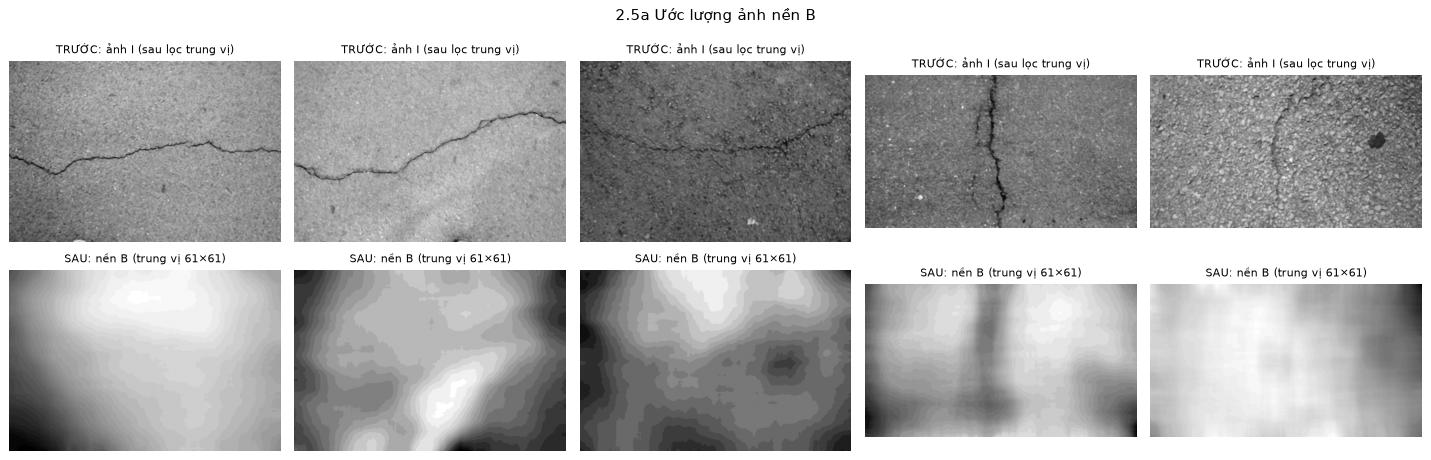

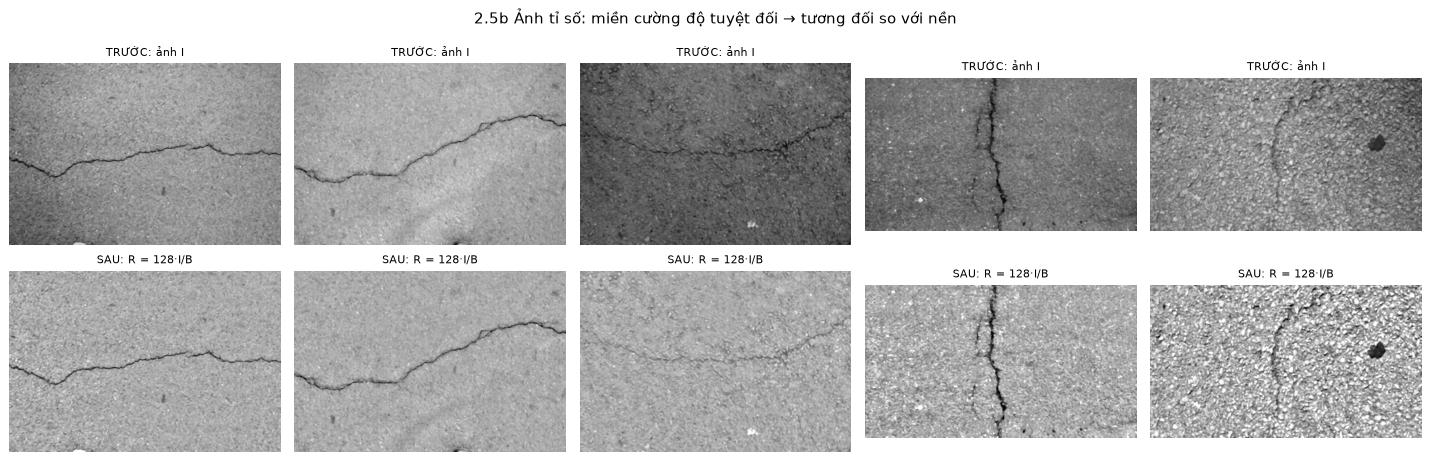

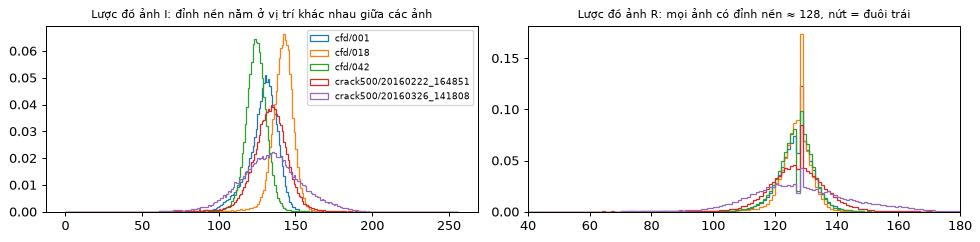

In [11]:
def illumination_ratio(gray, bg_ksize):
    bg = cv2.medianBlur(gray, bg_ksize)
    ratio = np.clip(128.0 * gray.astype(np.float32) / (bg.astype(np.float32) + 1.0), 0, 255).astype(np.uint8)
    return ratio, bg

S_RATIO, S_BG = zip(*[illumination_ratio(m, P_DEMO["bg"]) for m in S_MED])
show_before_after(S_MED, S_BG, ["ảnh I (sau lọc trung vị)"] * 5, [f"nền B (trung vị {P_DEMO['bg']}×{P_DEMO['bg']})"] * 5,
                  "2.5a Ước lượng ảnh nền B")
show_before_after(S_MED, S_RATIO, ["ảnh I"] * 5, ["R = 128·I/B"] * 5,
                  "2.5b Ảnh tỉ số: miền cường độ tuyệt đối → tương đối so với nền", vmin_a=60, vmax_a=160)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for j in range(5):
    ax[0].hist(S_MED[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=S_NAME[j])
    ax[1].hist(S_RATIO[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=S_NAME[j])
ax[0].set_title("Lược đồ ảnh I: đỉnh nền nằm ở vị trí khác nhau giữa các ảnh")
ax[1].set_title("Lược đồ ảnh R: mọi ảnh có đỉnh nền ≈ 128, nứt = đuôi trái")
ax[1].set_xlim(40, 180); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [12]:
# Gộp toàn bộ bước 2 thành một hàm
def preprocess(img, p):
    out = {"resized": resize_long_side(img, p["size"])}
    out["gray"] = to_gray(out["resized"])
    g = cv2.equalizeHist(out["gray"]) if p.get("equalize") else out["gray"]
    out["denoised"] = cv2.medianBlur(g, p["median"]) if p["median"] > 1 else g
    if p["bg"] > 1:
        out["ratio"], out["background"] = illumination_ratio(out["denoised"], p["bg"])
    else:  # dùng cho thí nghiệm "không bù chiếu sáng"
        out["ratio"], out["background"] = out["denoised"], None
    return out

---
# Bước 3 – Xử lý chính: tách ngưỡng tự động (Chương 5)

## 3.1 Làm trơn lược đồ (Ch5, tr.62)
Lược đồ của một ảnh 480×320 có nhiều dao động nhỏ, có thể tạo ra các đỉnh giả. Theo giáo trình, ta làm trơn lược đồ bằng **trung bình trượt cửa sổ W** (W lẻ, thường là 3 hoặc 5). Phép này không làm dịch vị trí đỉnh.
* **Tham số:** `hist_w ∈ {1 (tắt), 3, 5}`, chọn bằng tìm theo lưới.
* **Giá trị chọn: `hist_w = 3` cho cả hai tập.** Dice tune: CFD 0.481 / **0.516** / 0.510; CRACK500 0.572 / **0.638** / 0.634 (theo thứ tự W = 1 / 3 / 5). Khi không làm trơn, các dao động nhỏ ở vùng đuôi làm điểm có khoảng cách lớn nhất tới Δ "nhảy" thất thường giữa các ảnh, nên ngưỡng không ổn định.

## 3.2 Ngưỡng tam giác – phương pháp chính (Ch5, tr.78)
* **Dùng gì:** thuật toán tam giác của Zack.
  1. Nối đỉnh lược đồ (b_max) với mức khác 0 xa nhất về **phía đuôi** (b_min) bằng đường thẳng Δ.
  2. Với mỗi b nằm giữa b_min và b_max, tính khoảng cách d từ h[b] tới Δ.
  3. Ngưỡng θ là giá trị b có **d lớn nhất**. Pixel có R < θ được gán là **vết nứt**.
* **Tại sao chọn tam giác:**
  * Lược đồ ảnh R có **một đỉnh rất lớn** (nền, khoảng 98% pixel) và một **đuôi dài mỏng** về phía tối (vết nứt, khoảng 2%). Theo giáo trình, đây chính là loại lược đồ mà phương pháp tam giác được thiết kế cho.
  * **Otsu** giả định lược đồ có **hai đỉnh**, và khi một lớp chỉ chiếm 2% thì phương sai giữa hai lớp bị lớp nền chi phối. Kết quả là Otsu đặt ngưỡng vào giữa đỉnh nền và báo khoảng 25–50% ảnh là vết nứt (trên ảnh minh họa bên dưới: 27.5%, trong khi GT chỉ có 1.2%).
  * **Isodata** có cùng nhược điểm với Otsu, vì cũng dựa trên trung bình của hai lớp.
  * **Đối xứng nền** (tr.76) cũng hợp với loại lược đồ này, nhưng cần thêm tham số p% và hệ số khoảng cách. Phương pháp này được giữ lại làm biến thể để so sánh (mục 3.4).
  * Tam giác **không có tham số** và **tự thích nghi theo từng ảnh**, vì θ được tính lại cho mỗi ảnh.

In [13]:
def smooth_hist(img, w=5):
    h = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    if w > 1:
        h = np.convolve(np.pad(h, w // 2, mode="edge"), np.ones(w) / w, mode="valid")
    return h

def triangle(hist):
    """Zack: Δ nối (b_min, h[b_min]) và (b_max, h[b_max]); θ = argmax khoảng cách. Đuôi đối tượng ở phía TỐI."""
    bmax = int(np.argmax(hist)); bmin = int(np.nonzero(hist > 0)[0][0])
    if bmax == bmin:
        return bmax
    b = np.arange(bmin, bmax + 1)
    x1, y1, x2, y2 = bmin, hist[bmin], bmax, hist[bmax]
    d = np.abs((y2 - y1) * b - (x2 - x1) * hist[b] + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(b[np.argmax(d)])

def background_symmetry(hist, p=0.95):
    """Ch5 tr.76 (đối tượng TỐI hơn nền): maxp = đỉnh; a: P(z ≤ a) = p (phía sáng, không có đối tượng);
    θ = maxp − (a − maxp)."""
    maxp = int(np.argmax(hist)); c = np.cumsum(hist) / hist.sum()
    a = max(int(np.searchsorted(c, p)), maxp + 1)
    return maxp, a

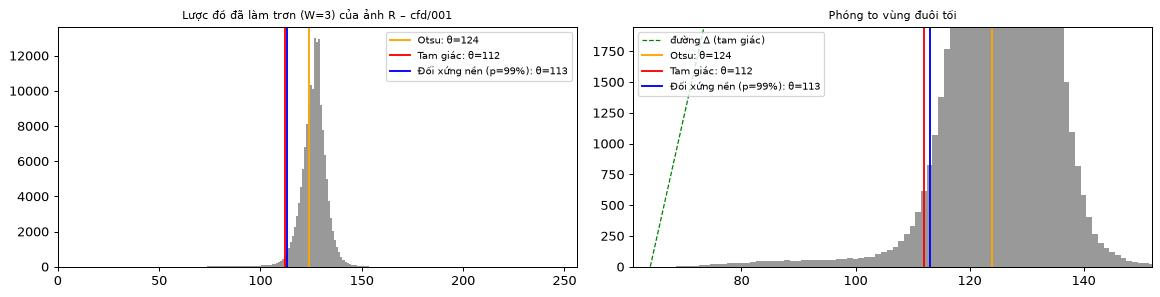

Tỉ lệ pixel bị gán nứt:  Otsu 27.5%   Tam giác 2.1%   Đối xứng nền 2.5%   | GT: 1.2%


In [14]:
# Minh họa trên 1 ảnh mẫu: lược đồ của R, so sánh vị trí ngưỡng Otsu / tam giác / đối xứng nền
j = 0
r = S_RATIO[j]; h = smooth_hist(r, P_DEMO["hist_w"])
t_tri = triangle(h)
t_otsu, _ = cv2.threshold(r, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
maxp, a = background_symmetry(h, 0.99); t_sym = maxp - (a - maxp)
bmin = int(np.nonzero(h > 0)[0][0])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for k, lim in enumerate([(0, 256), (bmin - 3, maxp + 25)]):
    ax[k].bar(np.arange(256), h, width=1, color="0.6")
    if k == 1:
        ax[k].plot([bmin, maxp], [h[bmin], h[maxp]], "g--", lw=1, label="đường Δ (tam giác)")
    for t, c, n in [(t_otsu, "orange", "Otsu"), (t_tri, "red", "Tam giác"), (t_sym, "blue", "Đối xứng nền (p=99%)")]:
        ax[k].axvline(t, color=c, lw=1.5, label=f"{n}: θ={t:.0f}")
    ax[k].set_xlim(*lim); ax[k].legend(fontsize=8)
ax[0].set_title(f"Lược đồ đã làm trơn (W={P_DEMO['hist_w']}) của ảnh R – {S_NAME[j]}")
ax[1].set_title("Phóng to vùng đuôi tối"); ax[1].set_ylim(0, h[maxp] * 0.15)
plt.tight_layout(); plt.show()
print(f"Tỉ lệ pixel bị gán nứt:  Otsu {np.mean(r < t_otsu)*100:.1f}%   Tam giác {np.mean(r < t_tri)*100:.1f}%"
      f"   Đối xứng nền {np.mean(r < t_sym)*100:.1f}%   | GT: {S_GT[j].mean()*100:.1f}%")

Otsu đặt ngưỡng gần đỉnh nền nên gán gần một nửa ảnh là vết nứt. Ngưỡng tam giác nằm ở **chân** đỉnh nền, nơi bắt đầu đuôi tối, nên tỉ lệ pixel được gán nứt gần với GT hơn nhiều.

**Phân đoạn 5 ảnh mẫu bằng ngưỡng tam giác.** Đây là bước chuyển từ ảnh mức xám sang **ảnh nhị phân**:

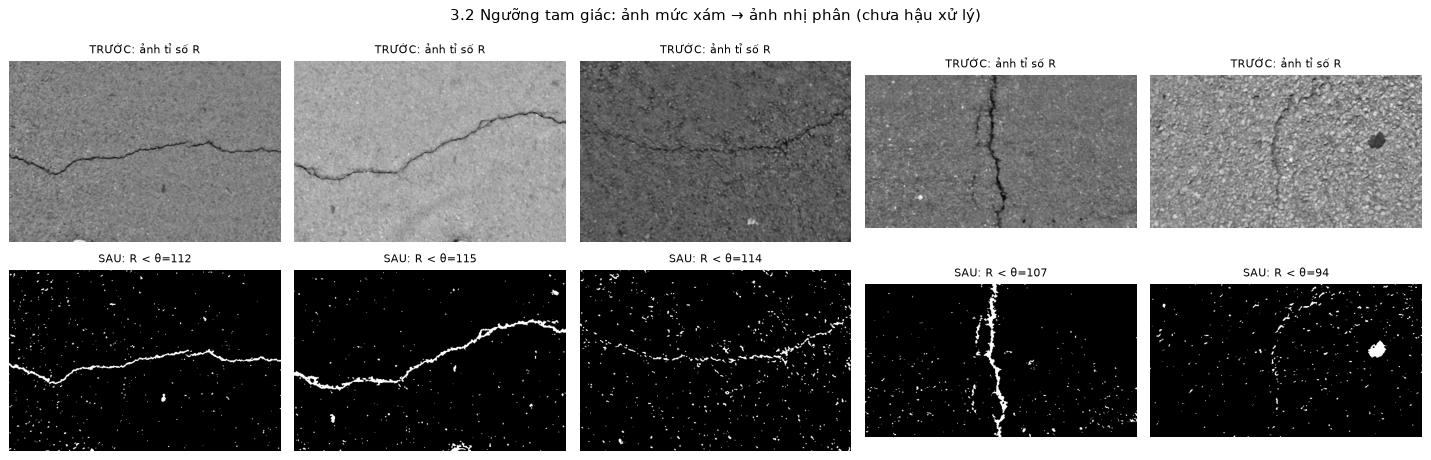

In [15]:
def seg_triangle(ratio, p):
    t = triangle(smooth_hist(ratio, p["hist_w"]))
    return ratio < t, {"theta": t}

S_RAW = [seg_triangle(r, P_DEMO)[0] for r in S_RATIO]
show_before_after(S_RATIO, [m.astype(np.uint8) * 255 for m in S_RAW],
                  ["ảnh tỉ số R"] * 5, [f"R < θ={seg_triangle(r, P_DEMO)[1]['theta']}" for r in S_RATIO],
                  "3.2 Ngưỡng tam giác: ảnh mức xám → ảnh nhị phân (chưa hậu xử lý)", vmin_a=0, vmax_a=255)

Kết quả đã bắt được hầu hết vết nứt, nhưng vẫn còn nhiều **đốm nhiễu nhỏ** (hạt sỏi tối) và vết nứt có chỗ **bị đứt quãng**. Hai lỗi này được xử lý ở bước 4.

## 3.3 Biến thể A: Sobel ∩ ngưỡng tam giác (Ch5: gradient, toán tử Sobel)
* **Ý tưởng** (theo pipeline gợi ý: Canny/Sobel kết hợp tách ngưỡng): vết nứt vừa **tối** vừa nằm ở nơi có **biến thiên cường độ mạnh**.
  * Độ lớn gradient Sobel `|∇f| = √(Gx² + Gy²)` (mặt nạ 3×3) được tách ngưỡng bằng Otsu để lấy biên mạnh.
  * Mặt nạ biên được giãn (`dil×dil`) vì một vết nứt mảnh cho **hai biên** nằm sát hai bờ, giãn ra mới phủ kín thân vết nứt.
  * Kết quả: mặt nạ = (R < θ_tam_giác) ∩ biên.
* **Tham số:** `dil ∈ {3, 5}`. Các tham số khác giống phương pháp chính.
* Otsu dùng **hợp lý** ở đây: lược đồ của |∇f| có hai nhóm rõ ràng hơn (vùng phẳng và vùng biên), khác với lược đồ R chỉ có một đỉnh.

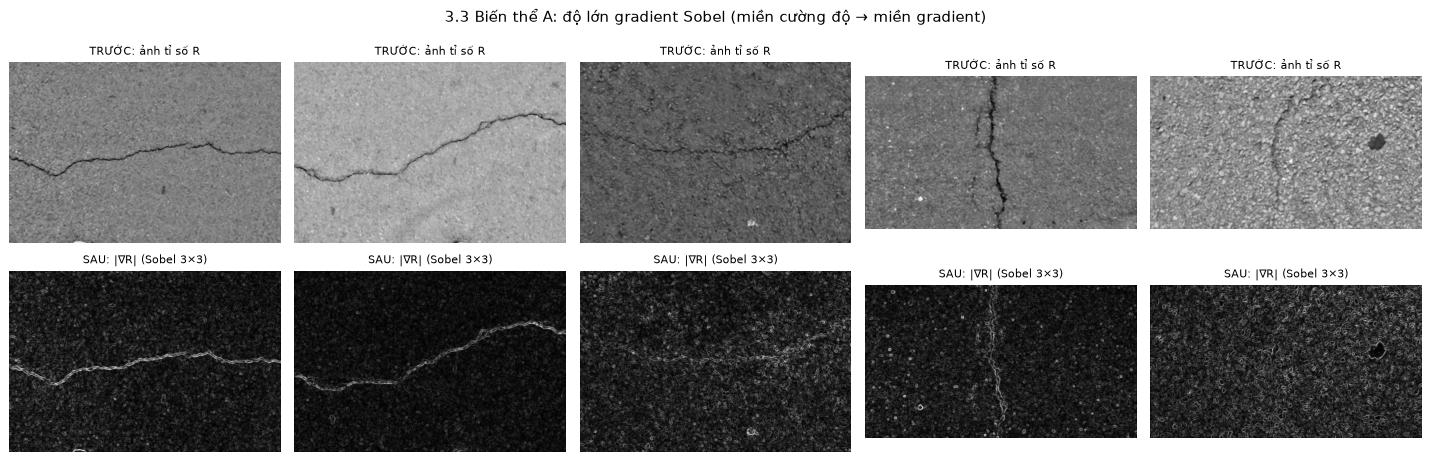

In [16]:
def sobel_magnitude(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.normalize(cv2.magnitude(gx, gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def seg_tri_sobel(ratio, p):
    dark, info = seg_triangle(ratio, p)
    _, edge = cv2.threshold(sobel_magnitude(ratio), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    edge = cv2.dilate(edge, np.ones((p["dil"], p["dil"]), np.uint8)) > 0
    return dark & edge, info

S_SOB = [sobel_magnitude(r) for r in S_RATIO]
show_before_after(S_RATIO, S_SOB, ["ảnh tỉ số R"] * 5, ["|∇R| (Sobel 3×3)"] * 5,
                  "3.3 Biến thể A: độ lớn gradient Sobel (miền cường độ → miền gradient)")

## 3.4 Biến thể B: đối xứng nền + phát triển vùng (Ch5: tr.76 và phân vùng dựa vào miền)
* **Ý tưởng:** dùng **ngưỡng kép** để vết nứt không bị đứt mà vẫn hạn chế nhiễu.
  * Ngưỡng đối xứng nền: θ_k = maxp − k·(a − maxp), trong đó a là điểm p% ở phía sáng.
  * **Hạt** (pixel chắc chắn là nứt): R < θ_high, với hệ số k_high.
  * **Ứng viên**: R < θ_low, với hệ số `low_ratio·k_high` (nới lỏng hơn).
  * **Phát triển vùng**: từ các hạt, giữ lại những vùng liên thông (8-láng giềng) của tập ứng viên có chứa ít nhất một hạt.
* **Tham số:** `sym_p ∈ {0.95, 0.99, 0.995}`, `k_high ∈ {1, 1.5, 2, 3}`, `low_ratio ∈ {0.5, 0.75, 1 (tắt phát triển vùng)}`.

In [17]:
def region_grow(seeds, candidates):
    n, lab = cv2.connectedComponents(candidates.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool); keep[np.unique(lab[seeds & candidates])] = True; keep[0] = False
    return keep[lab]

def seg_sym_grow(ratio, p):
    maxp, a = background_symmetry(smooth_hist(ratio, p["hist_w"]), p["sym_p"])
    t_high = maxp - p["k_high"] * (a - maxp)
    t_low = maxp - p["low_ratio"] * p["k_high"] * (a - maxp)
    seeds = ratio < t_high
    m = region_grow(seeds, ratio < t_low) if p["low_ratio"] < 1 else seeds
    return m, {"theta_high": t_high, "theta_low": t_low}

# Hai phương pháp đối chứng (baseline) – chỉ resize + ảnh xám, không tiền xử lý gì thêm
def baseline_otsu(gray):
    _, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)   # pixel tối hơn ngưỡng = nứt
    return m > 0

def baseline_canny(gray):
    return cv2.Canny(gray, 50, 150) > 0                                              # pixel biên = nứt

SEGMENTERS = {"tri": seg_triangle, "tri_sobel": seg_tri_sobel, "sym_grow": seg_sym_grow}

---
# Bước 4 – Hậu xử lý (Chương 7 + đặc trưng hình dạng Chương 8)

Thứ tự: **phép đóng → phép mở → lọc vùng theo diện tích → lọc vùng theo độ dãn dài.** Phần tử cấu trúc là hình **ellipse (đĩa)**: đẳng hướng, nên vết nứt theo hướng nào cũng được xử lý như nhau.

| Bước | Tham số (lưới tìm) | Lý do |
|---|---|---|
| **Phép đóng** A • B = (A ⊕ B) ⊖ B | `close ∈ {0, 3, 5, 7}` | Phép giãn rồi phép co: **lấp các khe nhỏ** hơn B, **nối** các đoạn vết nứt bị đứt (do vết nứt có chỗ hẹp hoặc sáng hơn) mà không làm dày vết nứt vĩnh viễn. |
| **Phép mở** A ∘ B = (A ⊖ B) ⊕ B | `open ∈ {0, 3}` | Phép co rồi phép giãn: **xóa đốm** nhỏ hơn B. Phép mở cũng xóa luôn vết nứt mảnh hơn B (CFD chỉ rộng 1–3 px) nên **có thể có hại**; để tập tune quyết định. |
| **Lọc vùng theo diện tích** | `a_min ∈ {0, 30, 60, 120, 200}` px | Gán nhãn **thành phần liên thông** (8-láng giềng, cùng nguyên lý với phát triển vùng và làm đầy vùng). Bỏ các vùng có diện tích < a_min: hạt sỏi tạo ra vùng nhỏ, còn vết nứt là vùng dài và lớn. |
| **Lọc theo độ dãn dài** | `e_min ∈ {0, 2, 3, 4}` | Đặc trưng hình dạng tính từ **mômen trung tâm bậc 2** (Ch8): độ dãn dài = √(λ₁/λ₂), với λ là trị riêng của ma trận [[μ₂₀, μ₁₁], [μ₁₁, μ₀₂]]. Vết nứt **dài và mảnh** nên λ₁ ≫ λ₂, còn vết dầu, ổ gà, đốm tối thì **gần tròn** (≈ 1). Vùng rất lớn (≥ 5·a_min) luôn được giữ, vì mạng nứt chằng chịt có thể có độ dãn thấp. |

In [18]:
def _se(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def elongation(comp):
    m = cv2.moments(comp.astype(np.uint8), binaryImage=True)
    mu20, mu02, mu11 = m["mu20"] / m["m00"], m["mu02"] / m["m00"], m["mu11"] / m["m00"]
    c = np.sqrt(((mu20 - mu02) / 2) ** 2 + mu11 ** 2)
    l1, l2 = (mu20 + mu02) / 2 + c, (mu20 + mu02) / 2 - c
    return float(np.sqrt(l1 / max(l2, 1e-6)))

def filter_regions(mask, a_min, e_min):
    if a_min <= 0 and e_min <= 0:
        return mask
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool)
    for i in range(1, n):
        area = st[i, cv2.CC_STAT_AREA]
        if area < a_min:
            continue
        if e_min > 0 and area < 5 * max(a_min, 1):
            x, y, w, h = st[i, :4]
            if elongation(lab[y:y + h, x:x + w] == i) < e_min:
                continue
        keep[i] = True
    return keep[lab]

def postprocess(mask, p, return_steps=False):
    steps = {"0. thô": mask}
    m = mask.astype(np.uint8)
    if p["close"] > 1:
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, _se(p["close"]))
    steps[f"1. đóng {p['close']}"] = m > 0
    if p["open"] > 1:
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, _se(p["open"]))
    steps[f"2. mở {p['open']}"] = m > 0
    m = filter_regions(m > 0, p["a_min"], 0)
    steps[f"3. diện tích ≥ {p['a_min']}"] = m
    m = filter_regions(m, p["a_min"], p["e_min"])
    steps[f"4. dãn dài ≥ {p['e_min']}"] = m
    return (m, steps) if return_steps else m

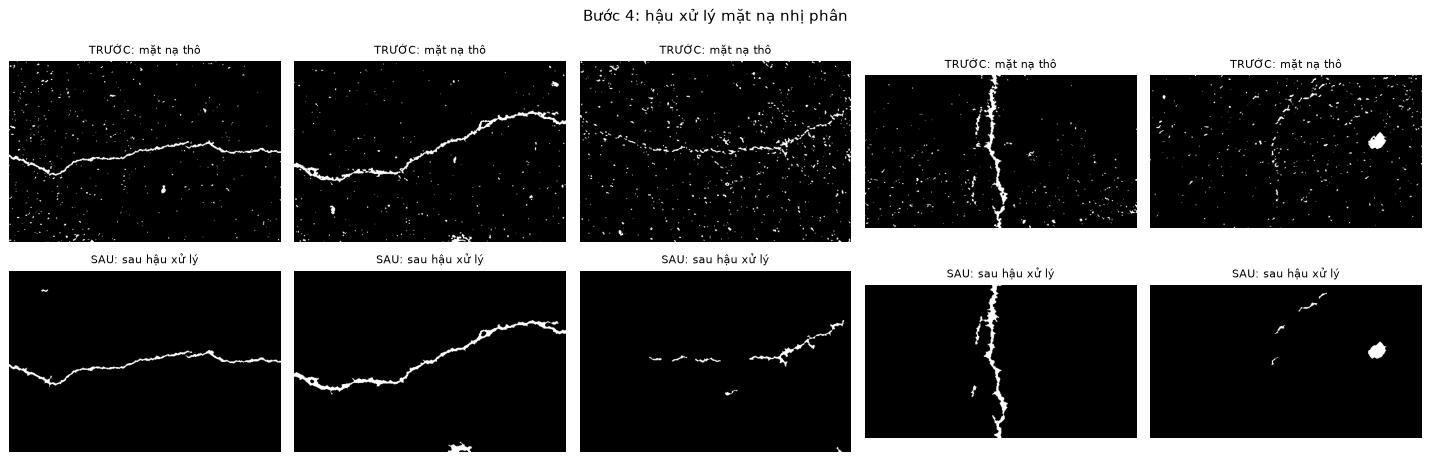

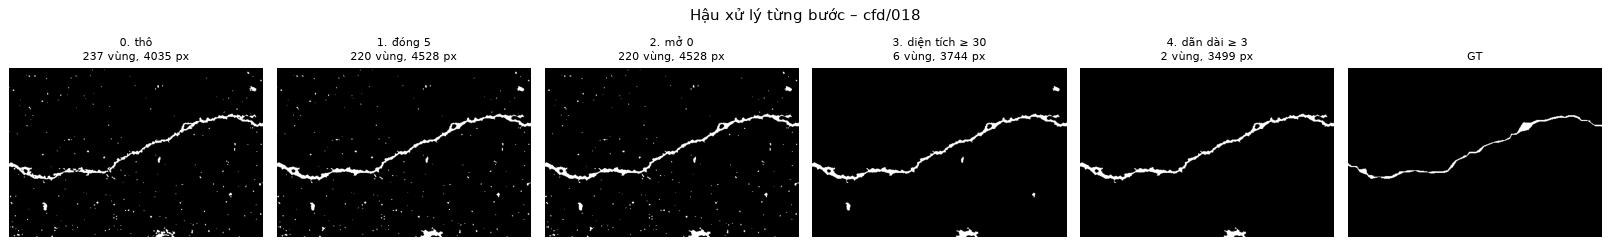

In [19]:
P_DEMO.update(close=5, open=0, a_min=30, e_min=3)   # = tham số hậu xử lý đã chọn cho CFD
S_POST = [postprocess(m, P_DEMO) for m in S_RAW]
show_before_after([m.astype(np.uint8) * 255 for m in S_RAW], [m.astype(np.uint8) * 255 for m in S_POST],
                  ["mặt nạ thô"] * 5, ["sau hậu xử lý"] * 5, "Bước 4: hậu xử lý mặt nạ nhị phân")

# Từng bước con trên 1 ảnh
_, steps = postprocess(S_RAW[1], P_DEMO, return_steps=True)
fig, ax = plt.subplots(1, len(steps) + 1, figsize=(18, 3))
for a, (k, v) in zip(ax, steps.items()):
    n = cv2.connectedComponents(v.astype(np.uint8), connectivity=8)[0] - 1
    a.imshow(v, cmap="gray"); a.set_title(f"{k}\n{n} vùng, {v.sum()} px"); a.axis("off")
ax[-1].imshow(S_GT[1], cmap="gray"); ax[-1].set_title("GT"); ax[-1].axis("off")
plt.suptitle(f"Hậu xử lý từng bước – {S_NAME[1]}"); plt.tight_layout(); plt.show()

---
# Chọn tham số trên tập tune (tìm kiếm theo lưới)

* **Tiêu chí:** **Dice trung bình theo ảnh** trên tập **tune**. Tập test **không** được dùng ở bước này.
* **Hai giai đoạn** (để giảm số tổ hợp cần thử):
  * **A.** Tìm theo lưới các tham số tiền xử lý và phân đoạn; tham số hậu xử lý cố định ở mức trung bình (close 5, open 0, a_min 60, e_min 3).
  * **B.** Giữ cấu hình tốt nhất của A, tìm theo lưới các tham số hậu xử lý.
* Mỗi tập dữ liệu được tìm tham số **riêng**, vì CFD (vết nứt mảnh, GT 1–3 px) và CRACK500 (vết nứt rộng, GT dày) khác nhau về bản chất.
* Mỗi phương pháp (chính, A, B) đều có lưới riêng để việc so sánh công bằng.

In [20]:
def to_original(mask, shape):
    return cv2.resize(mask.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST) > 0

def scores(pred, gt):
    tp = int(np.count_nonzero(pred & gt)); fp = int(np.count_nonzero(pred & ~gt)); fn = int(np.count_nonzero(~pred & gt))
    if tp + fp + fn == 0:
        return dict(tp=0, fp=0, fn=0, dice=1.0, iou=1.0, precision=1.0, recall=1.0)
    return dict(tp=tp, fp=fp, fn=fn, dice=2 * tp / (2 * tp + fp + fn), iou=tp / (tp + fp + fn),
                precision=tp / (tp + fp) if tp + fp else 0.0, recall=tp / (tp + fn) if tp + fn else 0.0)

def run(img, p):
    """Toàn bộ pipeline: ảnh gốc -> mặt nạ ở KÍCH THƯỚC GỐC (+ các ảnh trung gian)."""
    pp = preprocess(img, p)
    raw, info = SEGMENTERS[p["seg"]](pp["ratio"], p)
    m = postprocess(raw, p) if p.get("post", True) else raw
    return to_original(m, img.shape[:2]), {**pp, "raw": raw, "final_small": m, **info}

PRE = ("size", "equalize", "median", "bg")
POST_DEFAULT = dict(close=5, open=0, a_min=60, e_min=3)
POST_SPACE = dict(close=[0, 3, 5, 7], open=[0, 3], a_min=[0, 30, 60, 120, 200], e_min=[0, 2, 3, 4])
PRE_SPACE = dict(equalize=[False, True], median=[0, 3, 5], bg=[0, 21, 41, 61], hist_w=[1, 3, 5])
SPACES = {
    "tri":       PRE_SPACE,
    "tri_sobel": {**PRE_SPACE, "dil": [3, 5]},
    "sym_grow":  dict(equalize=[False], median=[3, 5], bg=[21, 41, 61], hist_w=[5],
                      sym_p=[0.95, 0.99, 0.995], k_high=[1.0, 1.5, 2.0, 3.0], low_ratio=[0.5, 0.75, 1.0]),
}

def grid(space):
    keys = list(space)
    for v in itertools.product(*(space[k] for k in keys)):
        yield dict(zip(keys, v))

def mean_dice(preds_gts):
    s = [scores(to_original(m, g.shape), g) for m, g in preds_gts]
    return {k: float(np.mean([x[k] for x in s])) for k in ("dice", "iou", "precision", "recall")}

def tune(ds, seg):
    # nạp tập tune 1 lần: ảnh đã resize (size cố định 480) + GT gốc
    data = []
    for sid in ids_of(ds, "tune"):
        img, gt = read_pair(ds, sid); data.append((resize_long_side(img, 480), gt))
    base = dict(size=480, seg=seg, **POST_DEFAULT)
    rec, cache, best_a, best_s = [], {}, None, -1
    for cfg in grid(SPACES[seg]):                                   # Giai đoạn A
        p = {**base, **cfg}
        key = tuple(p.get(k) for k in PRE)
        if key not in cache:
            cache = {key: [(preprocess(im, p)["ratio"], gt) for im, gt in data]}
        s = mean_dice([(postprocess(SEGMENTERS[seg](r, p)[0], p), gt) for r, gt in cache[key]])
        rec.append({"giai đoạn": "A", **cfg, **s})
        if s["dice"] > best_s:
            best_s, best_a = s["dice"], p
    raws = [(SEGMENTERS[seg](preprocess(im, best_a)["ratio"], best_a)[0], gt) for im, gt in data]
    best, best_s = best_a, -1
    for cfg in grid(POST_SPACE):                                     # Giai đoạn B
        p = {**best_a, **cfg}
        s = mean_dice([(postprocess(m, p), gt) for m, gt in raws])
        rec.append({"giai đoạn": "B", **cfg, **s})
        if s["dice"] > best_s:
            best_s, best = s["dice"], p
    return best, pd.DataFrame(rec)

In [21]:
BEST_PATH = os.path.join(RES, "best_params.json")
if RUN_TUNING or not os.path.exists(BEST_PATH):
    BEST, TUNE_LOG = {}, {}
    for ds in DATASETS:
        for seg in SPACES:
            t0 = time.time()
            BEST[(ds, seg)], TUNE_LOG[(ds, seg)] = tune(ds, seg)
            TUNE_LOG[(ds, seg)].to_csv(os.path.join(RES, f"tune_log_{ds}_{seg}.csv"), index=False)
            print(f"{ds:9s} {seg:10s} xong sau {time.time()-t0:5.0f}s – Dice tune tốt nhất "
                  f"{TUNE_LOG[(ds, seg)].dice.max():.3f}")
    json.dump({f"{d}|{s}": {k: (bool(v) if isinstance(v, np.bool_) else v) for k, v in p.items()}
               for (d, s), p in BEST.items()}, open(BEST_PATH, "w"), indent=1)
else:
    BEST = {tuple(k.split("|")): v for k, v in json.load(open(BEST_PATH)).items()}
    TUNE_LOG = {k: pd.read_csv(os.path.join(RES, f"tune_log_{k[0]}_{k[1]}.csv")) for k in BEST}

KEYS = ["equalize", "median", "bg", "hist_w", "dil", "sym_p", "k_high", "low_ratio", "close", "open", "a_min", "e_min"]
pd.DataFrame([{"tập": d, "phương pháp": s, **{k: BEST[(d, s)].get(k, "–") for k in KEYS},
               "Dice tune": TUNE_LOG[(d, s)].dice.max()} for d, s in BEST])

cfd       tri        xong sau    23s – Dice tune tốt nhất 0.518


cfd       tri_sobel  xong sau    37s – Dice tune tốt nhất 0.520


cfd       sym_grow   xong sau    41s – Dice tune tốt nhất 0.512


crack500  tri        xong sau    40s – Dice tune tốt nhất 0.638


crack500  tri_sobel  xong sau    59s – Dice tune tốt nhất 0.635


crack500  sym_grow   xong sau    64s – Dice tune tốt nhất 0.574


,tập,phương pháp,equalize,median,bg,hist_w,dil,sym_p,k_high,low_ratio,close,open,a_min,e_min,Dice tune
0,cfd,tri,False,3,61,3,–,–,–,–,5,0,30,3,0.518
1,cfd,tri_sobel,False,3,61,3,3,–,–,–,5,0,30,3,0.520
2,cfd,sym_grow,False,5,21,5,–,0.99,1.0,0.75,7,0,60,4,0.512
3,crack500,tri,False,3,41,3,–,–,–,–,5,0,60,3,0.638
4,crack500,tri_sobel,False,3,41,3,5,–,–,–,7,0,60,3,0.635
5,crack500,sym_grow,False,5,21,5,–,0.95,1.0,0.75,5,0,60,3,0.574


In [22]:
# Top-8 cấu hình giai đoạn A và B của phương pháp chính, cho từng tập
for ds in DATASETS:
    log = TUNE_LOG[(ds, "tri")]
    for st in ("A", "B"):
        cols = (["equalize", "median", "bg", "hist_w"] if st == "A" else ["close", "open", "a_min", "e_min"]) + ["dice", "iou", "precision", "recall"]
        print(f"\n=== {ds} – phương pháp chính – giai đoạn {st} (top 8 / {int((log['giai đoạn'] == st).sum())} cấu hình) ===")
        print(log[log["giai đoạn"] == st].sort_values("dice", ascending=False)[cols].head(8).to_string(index=False))


=== cfd – phương pháp chính – giai đoạn A (top 8 / 72 cấu hình) ===
equalize  median   bg  hist_w  dice   iou  precision  recall
   False     3.0 61.0     3.0 0.516 0.371      0.541   0.561
   False     3.0 41.0     3.0 0.513 0.369      0.554   0.544
   False     3.0 41.0     5.0 0.510 0.367      0.584   0.518
   False     3.0 61.0     5.0 0.508 0.366      0.560   0.533
   False     5.0 61.0     3.0 0.498 0.354      0.494   0.582
   False     0.0 61.0     3.0 0.496 0.350      0.567   0.511
   False     5.0 41.0     3.0 0.496 0.354      0.517   0.559
   False     0.0 41.0     3.0 0.491 0.345      0.581   0.489

=== cfd – phương pháp chính – giai đoạn B (top 8 / 160 cấu hình) ===
 close  open  a_min  e_min  dice   iou  precision  recall
   5.0   0.0   30.0    3.0 0.518 0.369      0.516   0.583
   5.0   0.0   60.0    3.0 0.516 0.371      0.541   0.561
   5.0   0.0   30.0    4.0 0.516 0.369      0.536   0.566
   5.0   0.0   60.0    2.0 0.514 0.366      0.523   0.570
   7.0   0.0   60.0   

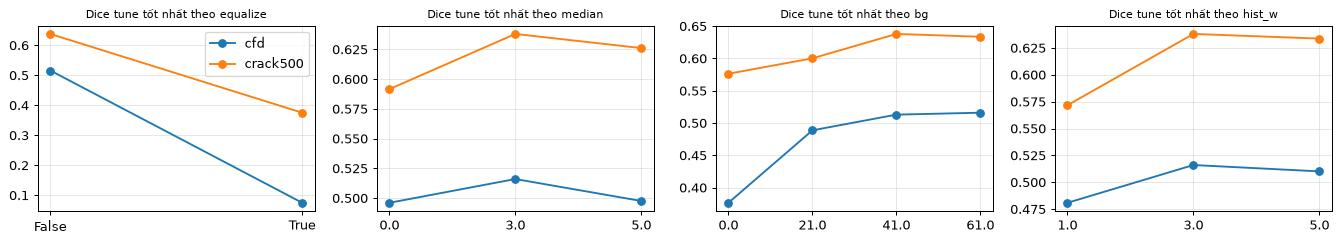

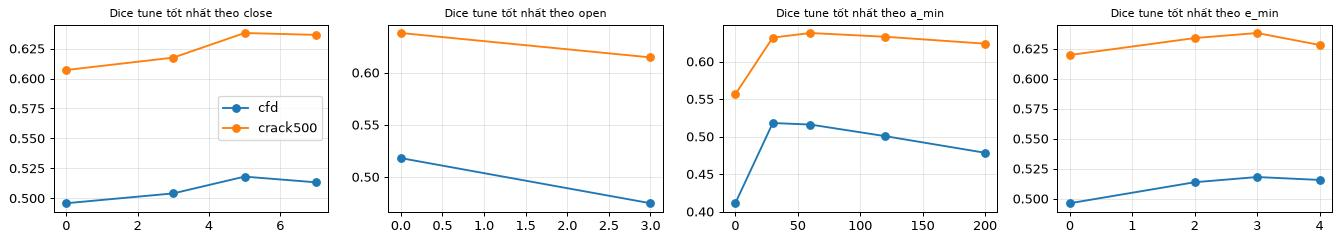

In [23]:
# Ảnh hưởng của từng tham số (giai đoạn A, phương pháp chính): Dice tune TỐT NHẤT khi cố định tham số đó
fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
for k, key in enumerate(["equalize", "median", "bg", "hist_w"]):
    for ds in DATASETS:
        log = TUNE_LOG[(ds, "tri")]; log = log[log["giai đoạn"] == "A"]
        g = log.groupby(log[key].astype(str))["dice"].max()
        ax[k].plot(g.index, g.values, "o-", label=ds)
    ax[k].set_title(f"Dice tune tốt nhất theo {key}"); ax[k].grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
for k, key in enumerate(["close", "open", "a_min", "e_min"]):
    for ds in DATASETS:
        log = TUNE_LOG[(ds, "tri")]; log = log[log["giai đoạn"] == "B"]
        g = log.groupby(key)["dice"].max()
        ax[k].plot(g.index, g.values, "o-", label=ds)
    ax[k].set_title(f"Dice tune tốt nhất theo {key}"); ax[k].grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()

### Phân tích kết quả chọn tham số

**Bảng tham số cuối cùng của phương pháp chính (M):**

| Bước | Tham số | CFD | CRACK500 | Lý do (Dice trên tập tune) |
|---|---|---|---|---|
| 2.1 | `size` | 480 | 480 | Cố định, bằng kích thước gốc của CFD (xem 2.1) |
| 2.3 | `equalize` | **Không** | **Không** | Bật cân bằng lược đồ thì Dice giảm mạnh: CFD 0.516 → 0.075, CRACK500 0.638 → 0.375 |
| 2.4 | `median` | 3 | 3 | Cân bằng giữa khử nhiễu và giữ vết nứt mảnh |
| 2.5 | `bg` | 61 | 41 | Tắt bù chiếu sáng thì giảm 0.06–0.14; CRACK500 có bóng đổ thay đổi nhanh hơn nên cần cửa sổ nhỏ hơn |
| 3.1 | `hist_w` | 3 | 3 | W = 3 giữ được hình dạng đuôi mà vẫn khử dao động nhỏ |
| 4 | `close` | 5 | 5 | Không đóng: CFD 0.496, CRACK500 0.607. Đóng k = 5 tốt nhất. k = 7 bắt đầu dính các nhánh nứt gần nhau lại thành mảng |
| 4 | `open` | **0 (tắt)** | **0 (tắt)** | Phép mở 3×3 **luôn có hại**: CFD 0.518 → 0.475, vì xóa luôn vết nứt rộng 1–2 px. Việc khử đốm do **lọc diện tích** đảm nhận |
| 4 | `a_min` | 30 | 60 | Không lọc diện tích: CFD 0.411, CRACK500 0.556. Đây là bước hậu xử lý **quan trọng nhất**. a_min quá lớn (200) thì mất các đoạn nứt ngắn |
| 4 | `e_min` | 3 | 3 | Lọc theo độ dãn dài tăng thêm khoảng 0.02, nhờ loại các đốm tối gần tròn (vết dầu, lỗ nhỏ) có diện tích lớn hơn a_min |

**Nhận xét.**
* Hai tập dữ liệu khác hẳn nhau nhưng chọn ra **gần như cùng một bộ tham số** (chỉ khác `bg` và `a_min`). Điều này cho thấy pipeline **ổn định** và không bị khớp quá mức (overfit) vào riêng một tập.
* **Cân bằng lược đồ là thất bại rõ nhất.** Nó kéo giãn đỉnh nền ra toàn dải [0, 255], làm lược đồ của R mất dạng "một đỉnh + đuôi". Ngưỡng tam giác khi đó rơi vào giữa vùng nền, và gần như toàn bộ ảnh bị gán là vết nứt.
* **So sánh các phương pháp xử lý chính trên tập tune:**
  * Tam giác: CFD 0.518, CRACK500 0.638
  * Sobel ∩ tam giác: CFD 0.520, CRACK500 0.635
  * Đối xứng nền + phát triển vùng: CFD 0.512, CRACK500 0.574

  Tam giác và Sobel ∩ tam giác **ngang nhau** (chênh lệch ≤ 0.003, mỗi phương pháp thắng ở một tập). Vì vậy chọn **tam giác** làm phương pháp chính, vì **đơn giản hơn** (không cần tính gradient và không có thêm tham số `dil`). Thông tin biên Sobel gần như trùng với thông tin "tối hơn nền" sau khi đã bù chiếu sáng, nên không bổ sung được gì nhiều.

---
# Bước 5 – Đánh giá trên tập test

### Độ đo (Ch8: ma trận nhầm lẫn)
Các độ đo tính trên từng pixel, ở **độ phân giải gốc** của ảnh:

$$\text{Dice} = \frac{2TP}{2TP + FP + FN} \;(= \text{F1 mức pixel}), \qquad \text{IoU} = \frac{TP}{TP + FP + FN}$$

* Kèm theo **Precision** = TP/(TP+FP) và **Recall** = TP/(TP+FN) để biết lỗi chủ yếu đến từ **báo nhầm** hay **bỏ sót**.
* Báo cáo **trung bình theo ảnh ± độ lệch chuẩn** (mỗi ảnh có trọng số như nhau) và **độ đo gộp** (cộng dồn TP, FP, FN của toàn tập rồi mới tính).
* Quan hệ giữa hai độ đo: IoU = Dice / (2 − Dice), nên IoU luôn ≤ Dice.

### Các phương pháp được so sánh
| Mã | Phương pháp | Vai trò |
|---|---|---|
| **B1** | Ảnh xám → **Otsu** toàn cục (pixel tối = nứt) | Đối chứng |
| **B2** | Ảnh xám → **Canny** (50/150) (pixel biên = nứt) | Đối chứng |
| **M** | Pipeline đầy đủ với **ngưỡng tam giác** | **Phương pháp chính** |
| V-A | Pipeline đầy đủ với Sobel ∩ tam giác | Biến thể (theo gợi ý) |
| V-B | Pipeline đầy đủ với đối xứng nền + phát triển vùng | Biến thể |
| Ab-1 … Ab-5 | M nhưng **bỏ hoặc thay đổi một bước** | Nghiên cứu cắt bỏ: chứng minh từng bước có đóng góp |

Tất cả dùng tham số đã chọn trên tập tune. Các thí nghiệm Ab dùng tham số của M và chỉ thay đổi đúng một bước.

In [24]:
def methods_for(ds):
    pm = BEST[(ds, "tri")]
    return {
        "B1 Otsu (đối chứng)": ("otsu", None),
        "B2 Canny (đối chứng)": ("canny", None),
        "M  Tam giác + đầy đủ (CHÍNH)": ("pipe", pm),
        "V-A Sobel ∩ tam giác": ("pipe", BEST[(ds, "tri_sobel")]),
        "V-B Đối xứng nền + phát triển vùng": ("pipe", BEST[(ds, "sym_grow")]),
        "Ab-1 M không bù chiếu sáng": ("pipe", {**pm, "bg": 0}),
        "Ab-2 M không lọc trung vị": ("pipe", {**pm, "median": 0}),
        "Ab-3 M + cân bằng lược đồ": ("pipe", {**pm, "equalize": True}),
        "Ab-4 M không hậu xử lý": ("pipe", {**pm, "post": False}),
        "Ab-5 M chỉ hình thái (không lọc vùng)": ("pipe", {**pm, "a_min": 0, "e_min": 0}),
    }

def predict(kind, p, img):
    if kind == "pipe":
        return run(img, p)[0]
    g = to_gray(resize_long_side(img, 480))
    return to_original(baseline_otsu(g) if kind == "otsu" else baseline_canny(g), img.shape[:2])

PER_IMAGE = {}
t0 = time.time()
for ds in DATASETS:
    M = methods_for(ds); rows = []
    for sid in ids_of(ds, "test"):
        img, gt = read_pair(ds, sid)
        for name, (kind, p) in M.items():
            rows.append({"id": sid, "phương pháp": name, **scores(predict(kind, p, img), gt)})
    PER_IMAGE[ds] = pd.DataFrame(rows)
    PER_IMAGE[ds].to_csv(os.path.join(RES, f"test_per_image_{ds}.csv"), index=False)
print(f"Đánh giá xong sau {time.time()-t0:.0f}s")

def summary(df):
    g = df.groupby("phương pháp", sort=False)
    out = pd.DataFrame({
        "Dice (TB±std)": g.dice.mean().map("{:.3f}".format) + " ± " + g.dice.std().map("{:.3f}".format),
        "IoU (TB±std)": g.iou.mean().map("{:.3f}".format) + " ± " + g.iou.std().map("{:.3f}".format),
        "Precision": g.precision.mean(), "Recall": g.recall.mean(),
    })
    s = g[["tp", "fp", "fn"]].sum()
    out["Dice gộp"] = 2 * s.tp / (2 * s.tp + s.fp + s.fn)
    out["IoU gộp"] = s.tp / (s.tp + s.fp + s.fn)
    out.insert(0, "số ảnh", g.size())
    return out

SUMMARY = {}
for ds in DATASETS:
    SUMMARY[ds] = summary(PER_IMAGE[ds]); SUMMARY[ds].to_csv(os.path.join(RES, f"test_summary_{ds}.csv"))
    print(f"\n================ {ds.upper()} – tập test ================")
    display(SUMMARY[ds])

Đánh giá xong sau 52s

================ CFD – tập test ================


,số ảnh,Dice (TB±std),IoU (TB±std),Precision,Recall,Dice gộp,IoU gộp
phương pháp,,,,,,,
B1 Otsu (đối chứng),58,0.058 ± 0.042,0.030 ± 0.024,0.030,0.879,0.056,0.029
B2 Canny (đối chứng),58,0.053 ± 0.076,0.029 ± 0.049,0.039,0.407,0.042,0.021
M Tam giác + đầy đủ (CHÍNH),58,0.575 ± 0.128,0.414 ± 0.121,0.596,0.616,0.587,0.415
V-A Sobel ∩ tam giác,58,0.584 ± 0.129,0.423 ± 0.124,0.618,0.612,0.597,0.425
V-B Đối xứng nền + phát triển vùng,58,0.528 ± 0.148,0.371 ± 0.123,0.543,0.605,0.553,0.382
Ab-1 M không bù chiếu sáng,58,0.476 ± 0.184,0.331 ± 0.157,0.544,0.475,0.503,0.336
Ab-2 M không lọc trung vị,58,0.566 ± 0.137,0.406 ± 0.126,0.635,0.563,0.574,0.403
Ab-3 M + cân bằng lược đồ,58,0.041 ± 0.028,0.021 ± 0.015,0.021,0.990,0.040,0.020
Ab-4 M không hậu xử lý,58,0.413 ± 0.106,0.266 ± 0.084,0.328,0.615,0.431,0.275



================ CRACK500 – tập test ================


,số ảnh,Dice (TB±std),IoU (TB±std),Precision,Recall,Dice gộp,IoU gộp
phương pháp,,,,,,,
B1 Otsu (đối chứng),200,0.076 ± 0.043,0.040 ± 0.024,0.041,0.883,0.071,0.037
B2 Canny (đối chứng),200,0.047 ± 0.023,0.024 ± 0.012,0.025,0.365,0.047,0.024
M Tam giác + đầy đủ (CHÍNH),200,0.549 ± 0.189,0.400 ± 0.165,0.622,0.564,0.490,0.324
V-A Sobel ∩ tam giác,200,0.556 ± 0.180,0.404 ± 0.158,0.578,0.619,0.475,0.312
V-B Đối xứng nền + phát triển vùng,200,0.511 ± 0.167,0.359 ± 0.142,0.517,0.605,0.539,0.369
Ab-1 M không bù chiếu sáng,200,0.479 ± 0.214,0.340 ± 0.181,0.549,0.502,0.517,0.348
Ab-2 M không lọc trung vị,200,0.415 ± 0.254,0.293 ± 0.201,0.479,0.616,0.156,0.085
Ab-3 M + cân bằng lược đồ,200,0.082 ± 0.115,0.048 ± 0.084,0.050,0.971,0.055,0.028
Ab-4 M không hậu xử lý,200,0.414 ± 0.140,0.270 ± 0.109,0.356,0.577,0.402,0.252


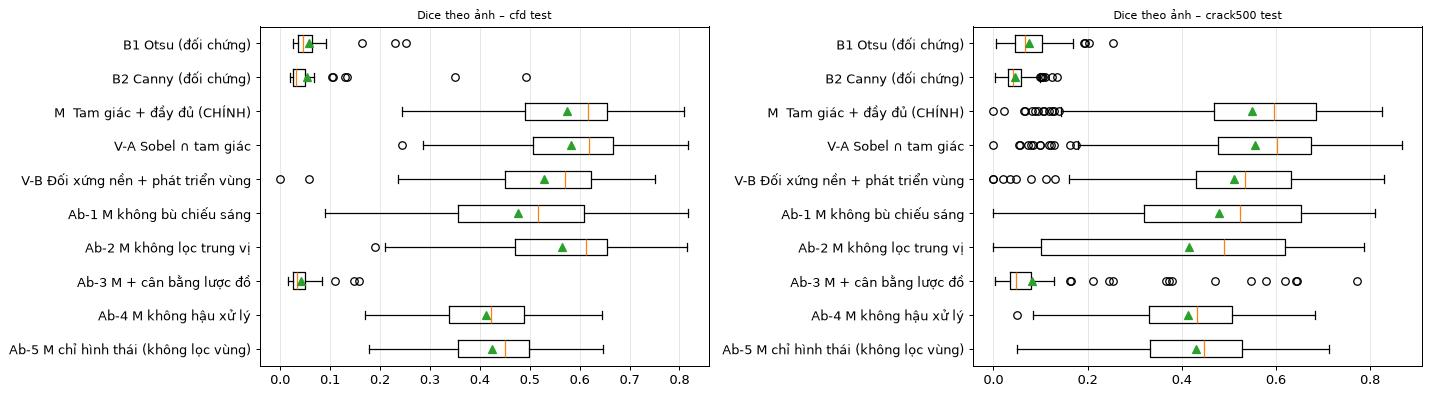

cfd {'Ab-1 M không bù chiếu sáng': '86%', 'Ab-2 M không lọc trung vị': '57%', 'Ab-3 M + cân bằng lược đồ': '100%', 'Ab-4 M không hậu xử lý': '95%', 'Ab-5 M chỉ hình thái (không lọc vùng)': '95%', 'B1 Otsu (đối chứng)': '100%', 'B2 Canny (đối chứng)': '100%', 'V-A Sobel ∩ tam giác': '16%', 'V-B Đối xứng nền + phát triển vùng': '76%'}
crack500 {'Ab-1 M không bù chiếu sáng': '73%', 'Ab-2 M không lọc trung vị': '67%', 'Ab-3 M + cân bằng lược đồ': '98%', 'Ab-4 M không hậu xử lý': '86%', 'Ab-5 M chỉ hình thái (không lọc vùng)': '84%', 'B1 Otsu (đối chứng)': '96%', 'B2 Canny (đối chứng)': '99%', 'V-A Sobel ∩ tam giác': '40%', 'V-B Đối xứng nền + phát triển vùng': '72%'}


In [25]:
# Phân bố Dice theo ảnh (tập test)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for k, ds in enumerate(DATASETS):
    df = PER_IMAGE[ds]; names = list(methods_for(ds))
    ax[k].boxplot([df[df["phương pháp"] == n].dice for n in names], orientation="horizontal", tick_labels=names, showmeans=True)
    ax[k].set_title(f"Dice theo ảnh – {ds} test"); ax[k].invert_yaxis(); ax[k].grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

# Kiểm định cặp đôi đơn giản: tỉ lệ ảnh mà M tốt hơn từng phương pháp khác
for ds in DATASETS:
    df = PER_IMAGE[ds].pivot(index="id", columns="phương pháp", values="dice")
    main = "M  Tam giác + đầy đủ (CHÍNH)"
    print(ds, {c: f"{(df[main] > df[c]).mean()*100:.0f}%" for c in df.columns if c != main})

### Trực quan hóa: phủ mặt nạ đỏ lên ảnh gốc (tập test)
Mỗi cột là một ảnh test. Các hàng lần lượt là: ảnh gốc, GT phủ đỏ, Otsu (B1), Canny (B2), phương pháp chính (M), và **bản đồ lỗi** của M.
Trên bản đồ lỗi: **xanh lá** = đúng (TP), **đỏ** = báo nhầm (FP), **xanh dương** = bỏ sót (FN).

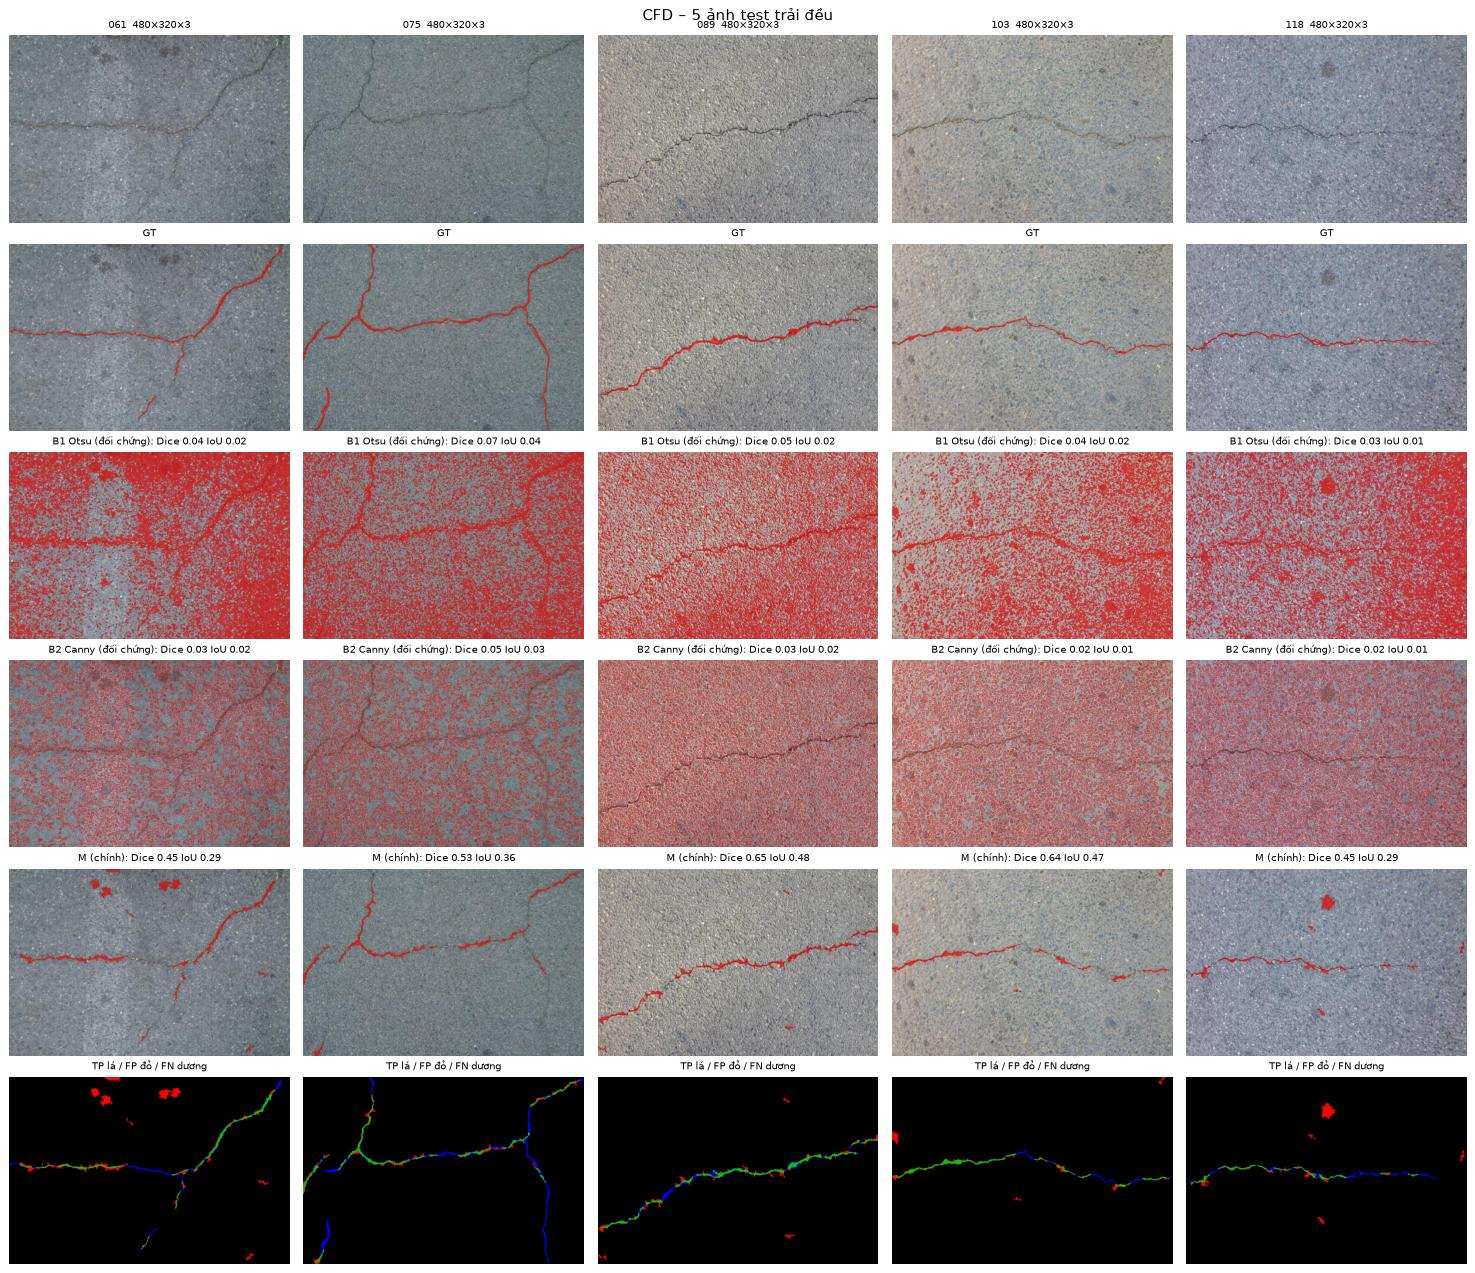

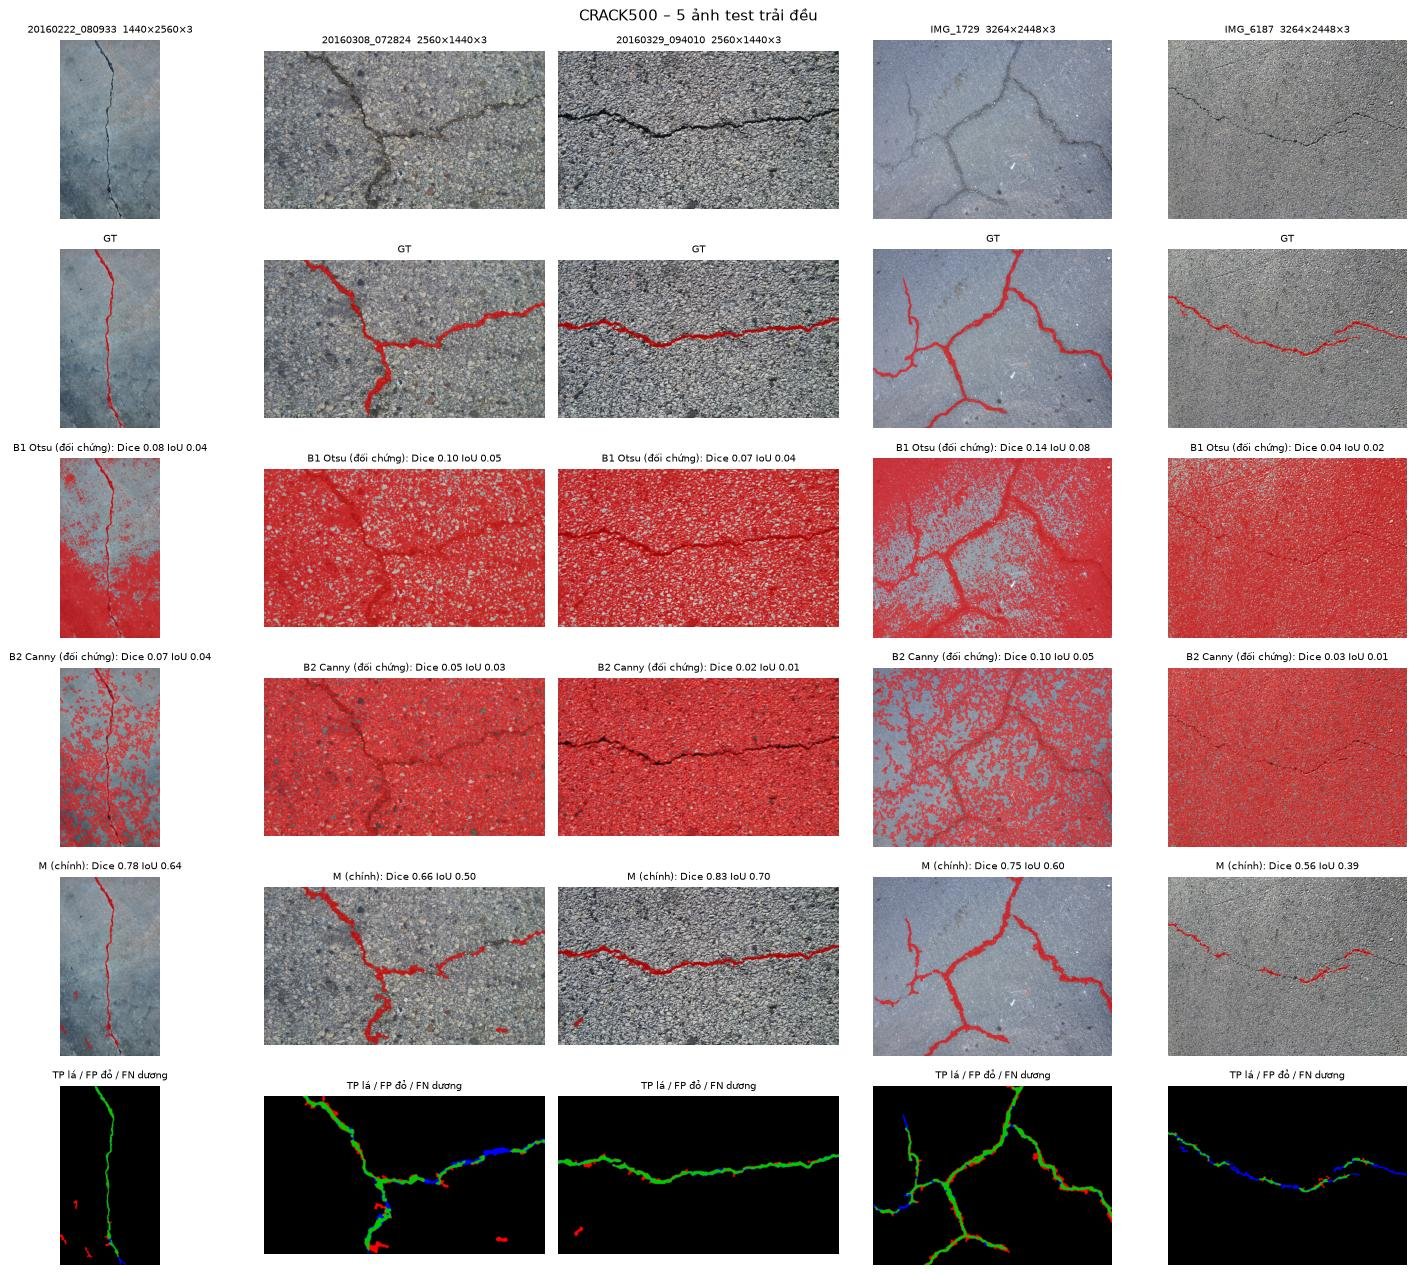

In [26]:
def show_test_grid(ds, ids, title):
    M = methods_for(ds)
    rows = [("Ảnh gốc", None), ("GT", None), ("B1 Otsu (đối chứng)", "B1 Otsu (đối chứng)"),
            ("B2 Canny (đối chứng)", "B2 Canny (đối chứng)"), ("M (chính)", "M  Tam giác + đầy đủ (CHÍNH)"), ("Bản đồ lỗi M", None)]
    fig, ax = plt.subplots(len(rows), len(ids), figsize=(3.3 * len(ids), 2.4 * len(rows)))
    for j, sid in enumerate(ids):
        img, gt = read_pair(ds, sid)
        th = 1 if img.shape[0] < 1000 else 7                      # làm dày nét để dễ nhìn trên ảnh lớn
        thick = lambda m: cv2.dilate(m.astype(np.uint8), np.ones((th, th))) > 0 if th > 1 else m
        for i, (lab, name) in enumerate(rows):
            if lab == "Ảnh gốc":
                vis, t = img, f"{sid}  {shp(img)}"
            elif lab == "GT":
                vis, t = overlay_red(img, thick(gt)), "GT"
            elif lab == "Bản đồ lỗi M":
                pm = predict(*M["M  Tam giác + đầy đủ (CHÍNH)"], img); vis, t = error_map(thick(pm), thick(gt)), "TP lá / FP đỏ / FN dương"
            else:
                pr = predict(*M[name], img); s = scores(pr, gt)
                vis, t = overlay_red(img, thick(pr)), f"{lab}: Dice {s['dice']:.2f} IoU {s['iou']:.2f}"
            ax[i, j].imshow(rgb(vis)); ax[i, j].set_title(t, fontsize=8); ax[i, j].axis("off")
    fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

for ds in DATASETS:
    ids = ids_of(ds, "test"); pick = [ids[k] for k in np.linspace(0, len(ids) - 1, 5).astype(int)]
    show_test_grid(ds, pick, f"{ds.upper()} – 5 ảnh test trải đều")

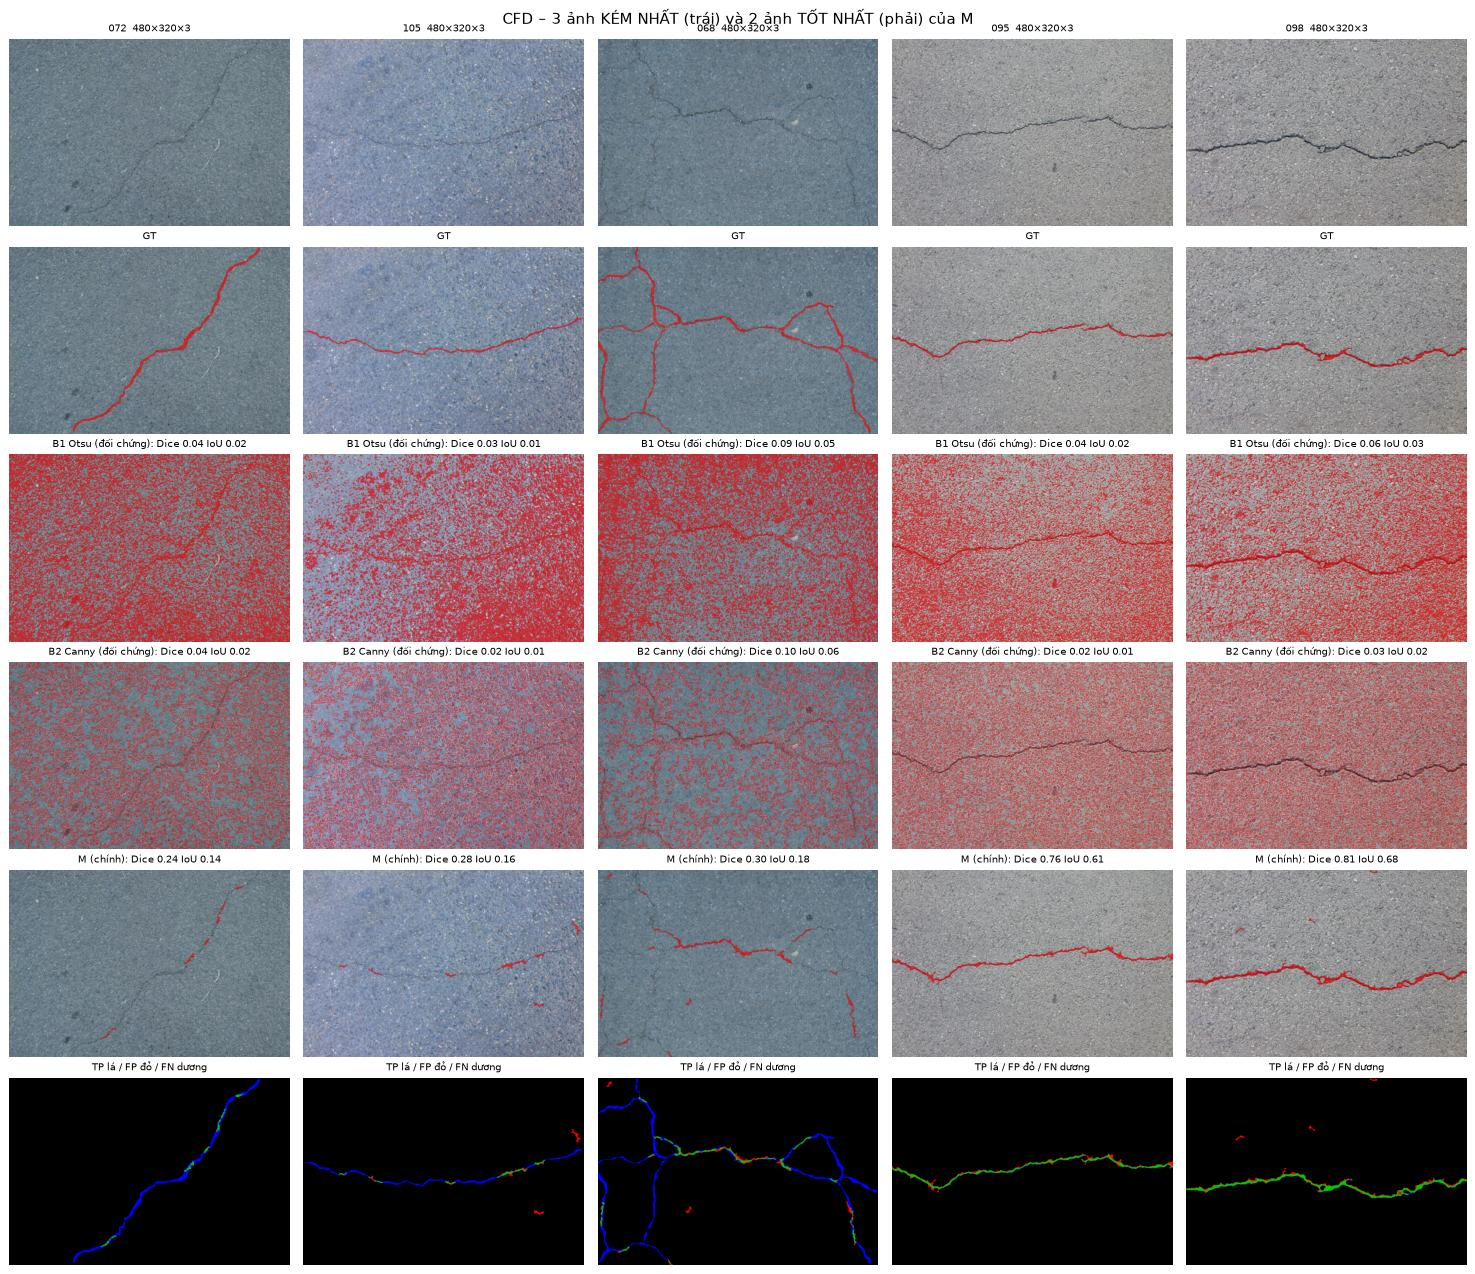

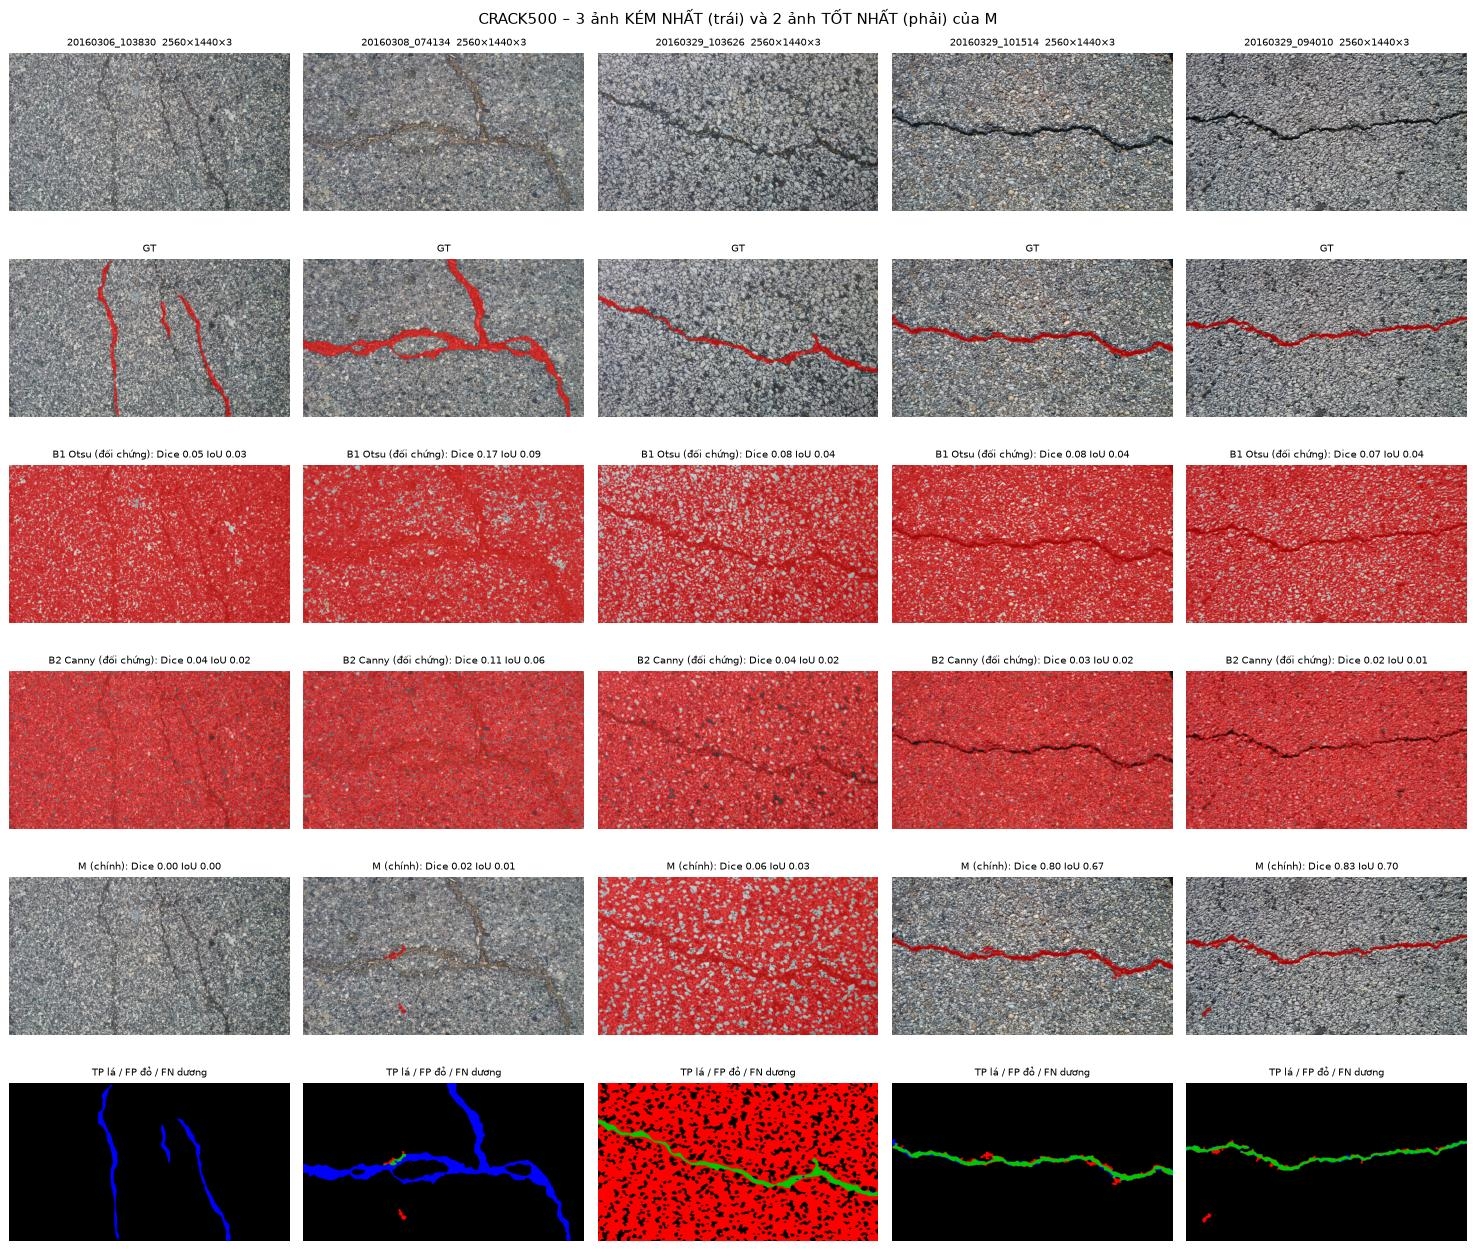

In [27]:
# Trường hợp tốt nhất / xấu nhất của phương pháp chính – để phân tích lỗi
for ds in DATASETS:
    d = PER_IMAGE[ds]; d = d[d["phương pháp"] == "M  Tam giác + đầy đủ (CHÍNH)"].sort_values("dice")
    show_test_grid(ds, list(d.id.head(3)) + list(d.id.tail(2)), f"{ds.upper()} – 3 ảnh KÉM NHẤT (trái) và 2 ảnh TỐT NHẤT (phải) của M")

In [28]:
# Lưu 5 ảnh mẫu mỗi tập vào samples/ (ảnh CRACK500 thu nhỏ cạnh dài 1280 để gọn file nộp) + chạy demo
SAMPLE_DIR = os.path.join(ROOT, "samples"); os.makedirs(SAMPLE_DIR, exist_ok=True)
for ds in DATASETS:
    ids = ids_of(ds, "test")
    for sid in [ids[k] for k in np.linspace(0, len(ids) - 1, 5).astype(int)]:
        img, gt = read_pair(ds, sid)
        if max(img.shape[:2]) > 1280:
            img = resize_long_side(img, 1280); gt = resize_long_side(gt.astype(np.uint8) * 255, 1280, cv2.INTER_NEAREST) > 127
        cv2.imwrite(os.path.join(SAMPLE_DIR, f"{ds}_{sid}.jpg"), img)
        cv2.imwrite(os.path.join(SAMPLE_DIR, f"{ds}_{sid}_gt.png"), gt.astype(np.uint8) * 255)
print(sorted(os.listdir(SAMPLE_DIR)))

['cfd_061.jpg', 'cfd_061_gt.png', 'cfd_075.jpg', 'cfd_075_gt.png', 'cfd_089.jpg', 'cfd_089_gt.png', 'cfd_103.jpg', 'cfd_103_gt.png', 'cfd_118.jpg', 'cfd_118_gt.png', 'crack500_20160222_080933.jpg', 'crack500_20160222_080933_gt.png', 'crack500_20160308_072824.jpg', 'crack500_20160308_072824_gt.png', 'crack500_20160329_094010.jpg', 'crack500_20160329_094010_gt.png', 'crack500_IMG_1729.jpg', 'crack500_IMG_1729_gt.png', 'crack500_IMG_6187.jpg', 'crack500_IMG_6187_gt.png']


---
# Thảo luận và kết luận

### Kết quả chính trên tập test (trung bình theo ảnh)

| Phương pháp | CFD Dice | CFD IoU | CRACK500 Dice | CRACK500 IoU |
|---|---|---|---|---|
| B1 Otsu (đối chứng) | 0.058 | 0.030 | 0.076 | 0.040 |
| B2 Canny (đối chứng) | 0.053 | 0.029 | 0.047 | 0.024 |
| **M – pipeline đầy đủ (tam giác)** | **0.575** | **0.414** | **0.549** | **0.400** |
| V-A Sobel ∩ tam giác | 0.584 | 0.423 | 0.556 | 0.404 |
| V-B Đối xứng nền + phát triển vùng | 0.528 | 0.371 | 0.511 | 0.359 |

1. **So với đối chứng:** pipeline tăng Dice **khoảng 10 lần**, từ khoảng 0.05–0.08 lên 0.55–0.58, và tốt hơn Otsu và Canny trên **96–100%** số ảnh test.
   * **Otsu** có recall khoảng 0.88 nhưng precision chỉ khoảng 0.03–0.04, tức là gán khoảng 25–50% ảnh là vết nứt. Nguyên nhân là lược đồ lệch lớp, đúng như phân tích ở mục 3.2.
   * **Canny** bắt cả biên của mọi hạt sỏi (kết cấu mặt đường), và chỉ cho đường biên hai bờ chứ không cho thân vết nứt.
2. **Kết quả tune và test khớp nhau:**
   * CFD: tune 0.518, test 0.575
   * CRACK500: tune 0.638, test 0.549

   Kết quả trên CRACK500 test thấp hơn tune vì tập test đa dạng hơn: có cả ảnh 3264×2448 từ thiết bị khác (`IMG_*`), trong khi tập tune gần như chỉ có ảnh 2560×1440. Không có dấu hiệu khớp quá mức nghiêm trọng.
3. **V-A (Sobel ∩ tam giác)** cao hơn M khoảng 0.01 Dice trung bình trên test, nhưng **thấp hơn** M về Dice gộp trên CRACK500 (0.475 so với 0.490). Trên tập tune, hai phương pháp hòa nhau. Vì phương pháp chính phải được chọn **trước** khi xem tập test, ta giữ M. Chênh lệch này nằm trong mức dao động giữa các ảnh (std khoảng 0.13–0.19).
4. **Nghiên cứu cắt bỏ:** mọi bước đều có đóng góp. Mức giảm Dice trung bình khi thay đổi từng bước, so với M:

   | Thay đổi | CFD | CRACK500 |
   |---|---|---|
   | Bỏ hậu xử lý (Ab-4) | −0.16 | −0.14 |
   | Bỏ bù chiếu sáng (Ab-1) | −0.10 | −0.07 |
   | Bỏ lọc trung vị (Ab-2) | −0.01 | −0.13 |
   | Thêm cân bằng lược đồ (Ab-3) | −0.53 | −0.47 |

   * Bỏ lọc trung vị gây hại lớn trên CRACK500 vì ảnh chứa nhiều sỏi to. Dice gộp giảm từ 0.49 xuống 0.16, do vài ảnh bị báo nhầm hàng loạt.
   * Lọc vùng theo diện tích và độ dãn dài chiếm phần lớn đóng góp của hậu xử lý: chỉ dùng hình thái (Ab-5) thì Dice chỉ còn khoảng 0.43.

### Phân tích lỗi (xem bản đồ lỗi và các ảnh kém nhất)
* **FN (bỏ sót)** tập trung ở đoạn vết nứt **mờ hoặc rất hẹp**, có độ tối gần với nền. Các đoạn này không vượt qua được ngưỡng tam giác, hoặc bị loại vì sau khi phân đoạn chỉ còn là các mảnh ngắn có diện tích < a_min.
* **FP (báo nhầm)** gồm các vệt tối dài nhưng **không phải vết nứt**: mép vạch sơn, vệt dầu, khe giữa các viên sỏi lớn, bóng của vật thể. Phương pháp chỉ dựa vào độ sáng và hình dạng nên không phân biệt được các trường hợp này.
* **Giới hạn của độ đo trên CFD:** GT chỉ rộng 1–3 px. Dự đoán lệch 1 px so với đường tâm vẫn bị tính là FP + FN, nên Dice trên CFD bị "phạt" nặng hơn so với trên CRACK500, nơi GT dày hơn.

### Hạn chế và hướng phát triển (trong phạm vi môn học)
* Ngưỡng là **toàn cục trong mỗi ảnh**. Ảnh có nhiều loại mặt đường khác nhau trong cùng khung hình sẽ cần ngưỡng cục bộ, ví dụ chia ảnh thành các khối rồi tách ngưỡng riêng cho từng khối.
* Có thể thêm **đặc trưng kết cấu GLCM/Haralick và bộ phân lớp kNN** (Ch8) để phân loại từng thành phần liên thông thành "nứt" hoặc "không nứt", thay cho các ngưỡng a_min và e_min đặt tay.
* Ảnh không có vết nứt: các tập dữ liệu dùng ở đây **ảnh nào cũng có vết nứt**, nên chưa đo được tỉ lệ báo động nhầm trên ảnh mặt đường lành.

### Tổng kết kiến thức đã dùng
| Chương | Kiến thức |
|---|---|
| C2 | Lấy mẫu lại, độ phân giải không gian (chuẩn hóa kích thước, đánh giá ở độ phân giải gốc) |
| C3 | Lọc trung vị (khử nhiễu và ước lượng nền), biến đổi điểm (ảnh tỉ số), cân bằng lược đồ (đã thử, bị loại) |
| C4 | Chuyển hệ màu RGB → ảnh xám |
| C5 | Làm trơn lược đồ, ngưỡng tam giác, Otsu, đối xứng nền, gradient Sobel, Canny, phát triển vùng |
| C7 | Phần tử cấu trúc, phép đóng, phép mở, thành phần liên thông |
| C8 | Đặc trưng hình dạng (mômen bậc 2, độ dãn dài), ma trận nhầm lẫn, Precision/Recall/F1 (= Dice) |